# 02 - Research statistics and features

## Objective and inputs
Read `artifacts/clean_market_data.parquet` from Notebook 1; construct the exact historical research features and study their statistical dependence.
This notebook owns feature engineering, segment/return audits, descriptive statistics and the correlation multitool.
It never reloads or recleans raw CSVs. Outputs feed Notebook 3 directly.

## Preserved methodology
Uninterrupted segments require the same delivery symbol and exactly one minute between adjacent rows of a source instrument.
Ambiguous timestamps isolate affected bars; returning to an earlier symbol does not reconnect its history.
Unknown prices remain in position and do not themselves split a time-continuous segment.
`bar_range = High - Low` remains in supplier price units. Volatility is the sample standard deviation of the last 30 log returns, including the current bar, with 30 finite returns required.
No new Open Interest transformation is introduced; the existing project used its level.

## Clarification and correction
The earlier return audit correctly reported undefined skewness/kurtosis for constant series, while the raw-feature summary inherited pandas' zero convention.
This notebook consistently reports `NaN` for both standardized moments when a feature has zero variance. This affects descriptive labels only, not features, correlations, signals or returns.
Missing values are never removed before a lag: lag 5 always means five original bar positions.

## Configuration and validated input
The exhaustive screen retains all 13 ordered feature pairs, absolute values on both sides, and lags 1, 2, 3, 5 and 10.
Third-party dependencies additionally include `threadpoolctl`; install packages in the selected kernel environment before running.

In [1]:
from pathlib import Path
from collections.abc import Mapping
from dataclasses import dataclass
from decimal import Decimal
from numbers import Integral, Real
import hashlib
import json
import time
import warnings
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
from scipy.stats import false_discovery_control, norm
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ARTIFACT_DIR = Path("artifacts")
CLEAN_PATH = ARTIFACT_DIR / "clean_market_data.parquet"
FEATURE_PATH = ARTIFACT_DIR / "research_features.parquet"
RESEARCH_DIR = ARTIFACT_DIR / "research"
AUDIT_DIR = RESEARCH_DIR / "segment_audit"
SCAN_DIR = RESEARCH_DIR / "correlations"
SEGMENTS_PATH = ARTIFACT_DIR / "segments.parquet"
SIGNIFICANT_PATH = ARTIFACT_DIR / "significant_combinations.csv"
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
RAW_FIELDS = {"open":"Open", "high":"High", "low":"Low", "close":"Close",
              "volume":"Volume", "money":"Turnover", "open_interest":"Open interest"}
FEATURE_FIELDS = ["log_return", "simple_return", "bar_range", "rolling_30m_volatility", "log1p_volume", "log1p_turnover"]
AVAILABLE_FEATURES = [*RAW_FIELDS.values(), *FEATURE_FIELDS]
TRANSFORMS = ("identity", "abs", "square")
DEFAULT_STATISTICS = ("mean", "std", "skew", "excess_kurtosis", "min", "median", "max")
DEFAULT_QUANTILES = (.001, .01, .05, .25, .5, .75, .95, .99, .999)
QUANTILE_METHODS = ("linear", "lower", "higher", "nearest", "midpoint")
QUANTILES = list(DEFAULT_QUANTILES)
PERCENTILES = ["0.1%", "1%", "5%", "25%", "median", "75%", "95%", "99%", "99.9%"]
RETURN_FIELDS = ["simple_return", "log_return"]
AUDIT_PARAMETERS = {"short_segment_bars_lt":31, "extreme_simple_return_pct_gt":[1,2,5,10],
    "std_ddof":1, "quantile_interpolation":"linear", "lag":1, "calendar_available":False,
    "winsorization":False, "rows_deleted":0}
SCAN_LAGS = [1,2,3,5,10]
SCAN_TRANSFORMS = ["abs"]
SCAN_BANDWIDTHS = [20,60]
SCAN_MIN_DATES = 90
SCAN_MIN_PAIRS = 2
SCAN_ALPHA = .05
if not CLEAN_PATH.exists():
    raise FileNotFoundError("Validated dataset not found. Run 01_data_quality_check.ipynb first.")
for folder in [RESEARCH_DIR, AUDIT_DIR, SCAN_DIR, SCAN_DIR / "by_file"]:
    folder.mkdir(parents=True, exist_ok=True)

def file_hash(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

clean_input_hash = file_hash(CLEAN_PATH)
clean_file = pq.ParquetFile(CLEAN_PATH)
if not {"instrument", "ID", "date", "symbol", *RAW_FIELDS}.issubset(clean_file.schema_arrow.names):
    raise ValueError("Validated dataset schema is incomplete; rerun Notebook 1.")
files = sorted(pd.read_parquet(CLEAN_PATH, columns=["instrument"]).instrument.unique().tolist())
print(f"Validated input: {len(files)} instruments; {clean_file.metadata.num_rows:,} bars")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .18, "figure.dpi": 120})

def show_table(frame, title, rows=15):
    probability_columns = {"p value", "p_screen", "q_by", "p_hac20", "p_hac60"}
    formats = {column: (lambda value: "NA" if not np.isfinite(value) else "<1e-300" if value == 0 else f"{value:.2e}")
               for column in frame.columns if column in probability_columns}
    display(frame.head(rows).style.hide(axis="index").format(formats, precision=6, na_rep="NA")
        .set_caption(title).set_properties(**{"padding": "5px 8px", "font-size": "12px"})
        .set_table_styles([{"selector": "th", "props": [("white-space", "normal"), ("max-width", "150px")]}]))
    if len(frame) > rows:
        print(f"Showing {rows:,} of {len(frame):,} rows; the complete table is exported.")

Validated input: 77 instruments; 44,011,860 bars


## Feature engineering: exact segment boundaries and backward-looking features
Both closes must be finite and strictly positive for simple/log returns. The log1p domain is finite `x > -1`, preserving the existing transformation rule even for flagged activity values.
At each segment start, returns and rolling volatility remain unknown. The normalized return used later is computed here, from simple return divided by positive finite current rolling volatility.

In [2]:
def safe_log1p(values):
    result = pd.Series(np.nan, index=values.index, dtype=float)
    defined = np.isfinite(values) & values.gt(-1)
    result.loc[defined] = np.log1p(values.loc[defined])
    return result

def build_segment_features(cleaned):
    """Stable chronological runs of one symbol, with exactly 60 s between bars.

    NaNs in prices do not delete rows or split a time-continuous run. Undefined
    features stay NaN; rolling windows need 30 observed returns in that run.
    """
    required = {"ID", "date", "symbol", *RAW_FIELDS}
    missing = required - set(cleaned.columns)
    if missing:
        raise ValueError(f"Missing input columns: {sorted(missing)}")
    bars = cleaned.copy()
    bars["date"] = pd.to_datetime(bars.date, errors="raise")
    bars = bars.sort_values(["date", "ID"], kind="stable", na_position="last").reset_index(drop=True)
    if bars.empty:
        raise ValueError("Empty input: no bars to segment")
    delta = bars.date.diff()
    same_symbol = bars.symbol.eq(bars.symbol.shift()) & bars.symbol.notna() & bars.symbol.shift().notna()
    aligned = bars.date.notna() & bars.date.eq(bars.date.dt.floor("min"))
    ambiguous_time = bars.date.duplicated(keep=False) & bars.date.notna()
    continuous = (
        delta.eq(pd.Timedelta(minutes=1)) & same_symbol
        & aligned & aligned.shift(fill_value=False)
        & ~ambiguous_time & ~ambiguous_time.shift(fill_value=False)
    ).fillna(False)
    bars["segment_id"] = (~continuous).cumsum().astype("int64")
    bars["segment_start"] = ~continuous
    bars["delta_minutes"] = delta.dt.total_seconds() / 60
    previous_close = bars.close.shift()
    usable_price_pair = (
        continuous & np.isfinite(bars.close) & np.isfinite(previous_close)
        & bars.close.gt(0) & previous_close.gt(0)
    )
    bars["simple_return"] = np.nan
    bars["log_return"] = np.nan
    bars.loc[usable_price_pair, "simple_return"] = (
        bars.loc[usable_price_pair, "close"] / previous_close.loc[usable_price_pair] - 1
    )
    bars.loc[usable_price_pair, "log_return"] = (
        np.log(bars.loc[usable_price_pair, "close"]) - np.log(previous_close.loc[usable_price_pair])
    )
    bars["bar_range"] = bars.high - bars.low
    rolling = bars.groupby("segment_id", sort=False).log_return.rolling(
        window=30, min_periods=30,
    ).std(ddof=1)
    bars["rolling_30m_volatility"] = rolling.droplevel(0).reindex(bars.index)
    bars["log1p_volume"] = safe_log1p(bars.volume)
    bars["log1p_turnover"] = safe_log1p(bars.money)
    return bars

### Segment summaries and lag-1 return persistence
Pearson coefficients use only finite adjacent endpoints inside the same segment. Subtracting a reference value before centering improves numerical stability for large price levels and constant sequences.

In [3]:
def segment_autocorrelation(returns, segment_ids, prefix):
    """Pearson corr(r[t-1], r[t]) using only adjacent, finite within-run pairs.

    Subtract a group's first pair before centering to keep constant series
    exactly constant and avoid cancellation. No pairs are formed across NaNs.
    """
    values = returns.to_numpy(dtype=float)
    ids = segment_ids.to_numpy(dtype=np.int64)
    size = int(ids.max()) + 1
    valid = (ids[1:] == ids[:-1]) & np.isfinite(values[1:]) & np.isfinite(values[:-1])
    group, x, y = ids[1:][valid], values[:-1][valid], values[1:][valid]
    count = np.bincount(group, minlength=size)
    present, first = np.unique(group, return_index=True)
    origin_x, origin_y = np.zeros(size), np.zeros(size)
    origin_x[present], origin_y[present] = x[first], y[first]
    x, y = x - origin_x[group], y - origin_y[group]
    mean_x = np.divide(np.bincount(group, weights=x, minlength=size), count,
                       out=np.zeros(size), where=count > 0)
    mean_y = np.divide(np.bincount(group, weights=y, minlength=size), count,
                       out=np.zeros(size), where=count > 0)
    x, y = x - mean_x[group], y - mean_y[group]
    cross = np.bincount(group, weights=x * y, minlength=size)
    norm = np.sqrt(np.bincount(group, weights=x * x, minlength=size)
                   * np.bincount(group, weights=y * y, minlength=size))
    corr = np.divide(cross, norm, out=np.full(size, np.nan), where=(count >= 2) & (norm > 0))
    return pd.DataFrame({
        "segment_id": np.arange(1, size),
        f"{prefix}_autocorr_lag1": np.clip(corr[1:], -1, 1),
        f"{prefix}_lag1_pairs": count[1:],
    }).set_index("segment_id")

In [4]:
def describe_segments(bars):
    segments = bars.groupby("segment_id", sort=True).agg(
        symbol=("symbol", "first"), start=("date", "min"), end=("date", "max"),
        rows=("ID", "size"), first_ID=("ID", "first"), last_ID=("ID", "last"),
        simple_return_count=("simple_return", "count"),
        log_return_count=("log_return", "count"),
        volatility_count=("rolling_30m_volatility", "count"),
    )
    for field in ["simple_return", "log_return"]:
        segments = segments.join(segment_autocorrelation(bars[field], bars.segment_id, field))
    return segments.reset_index()

def verify_segment_features(bars, segments):
    inside = ~bars.segment_start
    assert bars.loc[inside, "date"].sub(bars.date.shift().loc[inside]).eq(pd.Timedelta(minutes=1)).all()
    assert bars.loc[inside, "symbol"].eq(bars.symbol.shift().loc[inside]).all()
    assert bars.loc[bars.segment_start, ["simple_return", "log_return", "rolling_30m_volatility"]].isna().all().all()
    assert segments.rows.sum() == len(bars)
    assert segments.simple_return_count.sum() == bars.simple_return.notna().sum()
    assert segments.volatility_count.sum() == bars.rolling_30m_volatility.notna().sum()
    finite_return = bars.log_return.notna() & bars.simple_return.notna()
    np.testing.assert_allclose(np.expm1(bars.loc[finite_return, "log_return"]),
                               bars.loc[finite_return, "simple_return"], atol=1e-12, rtol=1e-10)

### Descriptive statistics and return audit definitions
Quantiles use linear interpolation; standard deviations use `ddof=1`; skewness and Fisher excess kurtosis use pandas' bias-corrected estimates.
Strict extreme-return counts use decimal source prices to resolve floating-point ties at 1%, 2%, 5% and 10%. No observation is removed by these diagnostics.

In [5]:
def distribution(values):
    values = pd.Series(np.asarray(values, dtype=float))
    finite = values.loc[np.isfinite(values)]
    result = {
        "count": len(finite), "missing_or_nonfinite": len(values) - len(finite),
        "mean": finite.mean(), "std": finite.std(ddof=1), "skew": finite.skew(),
        "excess_kurtosis": finite.kurt(), "min": finite.min(),
        **dict(zip(PERCENTILES, finite.quantile(QUANTILES).to_numpy())),
        "max": finite.max(),
    }
    if len(finite) and result["min"] == result["max"]:
        # Standardized third/fourth moments require nonzero variance. Pandas
        # returns 0 for constants; in an audit that must not imply normality.
        result["skew"] = np.nan
        result["excess_kurtosis"] = np.nan
    return result

def percentage(count, total):
    return 100.0 * count / total if total else np.nan

def pearson(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    if len(x) < 2 or np.ptp(x) == 0 or np.ptp(y) == 0:
        return np.nan
    # Center after subtracting a reference value, including constant sequences.
    x, y = x - x[0], y - y[0]
    x, y = x - x.mean(), y - y.mean()
    return float(np.clip(np.dot(x, y) / np.sqrt(np.dot(x, x) * np.dot(y, y)), -1, 1))

def strict_extreme_masks(returns, close, previous_close):
    """Keep returns untouched; resolve threshold-rounding ties in decimal prices."""
    finite = np.isfinite(returns)
    masks = {}
    for pct in AUDIT_PARAMETERS["extreme_simple_return_pct_gt"]:
        threshold = pct / 100
        mask = finite & (np.abs(returns) > threshold)
        near = finite & np.isclose(np.abs(returns), threshold, rtol=0, atol=1e-12)
        for i in np.flatnonzero(near):
            if np.isfinite(close[i]) and np.isfinite(previous_close[i]) and previous_close[i] > 0:
                current, previous = Decimal(str(close[i])), Decimal(str(previous_close[i]))
                mask[i] = abs(current - previous) * 100 > Decimal(pct) * previous
        masks[f"abs_return_gt_{pct}pct"] = mask
    return masks

### Boundary diagnostics
Reasons describe the observed data, not verified exchange sessions. Counts of individual reasons can overlap; reason combinations partition boundaries.

In [6]:
def boundary_audit(frame):
    """Describe existing boundaries; never create new segments or infer sessions."""
    previous_date = frame.date.shift()
    delta = (frame.date - previous_date).dt.total_seconds() / 60
    same_symbol = frame.symbol.eq(frame.symbol.shift()) & frame.symbol.notna() & frame.symbol.shift().notna()
    aligned = frame.date.notna() & frame.date.eq(frame.date.dt.floor("min"))
    duplicated = frame.date.duplicated(keep=False) & frame.date.notna()
    first = pd.Series(np.arange(len(frame)) == 0, index=frame.index)
    predicates = {
        "first_observation": first,
        "symbol_change": ~first & frame.symbol.notna() & frame.symbol.shift().notna() & ~same_symbol,
        "time_gap_gt_1m": ~first & delta.gt(1),
        "nonpositive_time_step": ~first & delta.le(0),
        "subminute_step": ~first & delta.gt(0) & delta.lt(1),
        "missing_timestamp": ~first & (frame.date.isna() | previous_date.isna()),
        "missing_symbol": ~first & (frame.symbol.isna() | frame.symbol.shift().isna()),
        "off_minute_timestamp": ~first & (~aligned | ~aligned.shift(fill_value=False)),
        "ambiguous_timestamp": ~first & (duplicated | duplicated.shift(fill_value=False)),
    }
    # segment_start and segment_id are consumed as saved, not rederived as preprocessing.
    starts = frame.segment_start.astype(bool)
    starts_from_ids = frame.segment_id.ne(frame.segment_id.shift())
    flags = pd.DataFrame(predicates)
    text = np.full(len(frame), "", dtype=object)
    for name in flags:
        mask = flags[name].to_numpy()
        text[mask] = text[mask] + name + ";"
    unexplained = starts & pd.Series(text == "", index=frame.index)
    text[unexplained.to_numpy()] = "unexplained_boundary;"
    columns = ["ID", "date", "symbol", "segment_id", "Close", "Volume"]
    context = frame[columns].copy()
    for column in ["ID", "date", "symbol", "segment_id", "Close"]:
        context[column + "_prev"] = frame[column].shift()
    context["delta_minutes"] = delta
    context["reason"] = pd.Series(text).str.rstrip(";")
    context["calendar_date_change"] = ~first & frame.date.dt.normalize().ne(previous_date.dt.normalize())
    context["gap_context"] = np.select(
        [first, delta.gt(1) & ~context.calendar_date_change, delta.gt(1) & context.calendar_date_change],
        ["first_observation", "same_calendar_date_gap", "calendar_date_change_gap"],
        default="no_gap_gt_1m",
    )
    context["session_classification"] = "not_assessed_without_calendar"
    boundaries = context.loc[starts].copy()
    reason_counts = [{"reason": name, "count": int((starts & mask).sum()),
                      "pct_of_boundaries": percentage(int((starts & mask).sum()), int(starts.sum()))}
                     for name, mask in predicates.items()]
    reason_counts.append({"reason": "unexplained_boundary", "count": int(unexplained.sum()),
                          "pct_of_boundaries": percentage(int(unexplained.sum()), int(starts.sum()))})
    combinations = boundaries.reason.value_counts().rename_axis("reason_combination").reset_index(name="count")
    combinations["pct_of_boundaries"] = combinations["count"] / len(boundaries) * 100
    temporal_defect = (~first & ~same_symbol) | ~delta.eq(1) | ~aligned | ~aligned.shift(fill_value=False) | duplicated | duplicated.shift(fill_value=False)
    integrity_flags = {
        "inside_segment_time_or_symbol_issue": (~starts & temporal_defect).to_numpy(),
        "segment_start_id_mismatch": starts.ne(starts_from_ids).to_numpy(),
        "unexplained_boundary": unexplained.to_numpy(),
    }
    pattern = boundaries.loc[~boundaries.reason.eq("first_observation")].copy()
    pattern["clock_prev"] = pattern.date_prev.dt.strftime("%H:%M")
    pattern["clock"] = pattern.date.dt.strftime("%H:%M")
    patterns = pattern.groupby(["clock_prev", "clock", "gap_context", "reason"], dropna=False).agg(
        boundaries=("ID", "size"), min_delta_minutes=("delta_minutes", "min"), max_delta_minutes=("delta_minutes", "max"),
    ).reset_index().sort_values("boundaries", ascending=False)
    return boundaries, pd.DataFrame(reason_counts), combinations, patterns, integrity_flags

### Per-instrument segment and return audit
Retain the original audit: short segments have fewer than 31 bars; compare zero/positive/missing/negative current volume, return tails, lag-1 persistence and flagged observations.

In [7]:
def audit_one_file(arrays, saved_segments, short_bars=31):
    required = ["ID", "date", "symbol", "segment_id", "segment_start", "Close", "Volume", *RETURN_FIELDS]
    lengths = {len(arrays[key]) for key in required}
    if len(lengths) != 1:
        raise ValueError("Existing arrays are not aligned")
    frame = pd.DataFrame({key: arrays[key] for key in required})
    frame["date"] = pd.to_datetime(frame.date)
    n = len(frame)
    segments = saved_segments.copy()
    if not n or segments.segment_id.duplicated().any():
        raise ValueError("Empty arrays or nonunique segment IDs")
    observed = frame.groupby("segment_id", sort=True).size()
    pd.testing.assert_series_equal(observed, segments.set_index("segment_id").rows.sort_index(), check_names=False)
    assert n == int(segments.rows.sum())
    grouped = frame.groupby("segment_id", sort=True)
    ids = frame.segment_id.to_numpy()
    starts = frame.segment_start.to_numpy(dtype=bool)
    r = frame.simple_return.to_numpy()
    lr = frame.log_return.to_numpy()
    finite = np.isfinite(r)
    volume = frame.Volume.to_numpy()
    close = frame.Close.to_numpy()
    previous_close = np.r_[np.nan, close[:-1]]
    volume_masks = {
        "volume = 0": np.isfinite(volume) & (volume == 0),
        "volume > 0": np.isfinite(volume) & (volume > 0),
        "volume missing/nonfinite": ~np.isfinite(volume),
        "volume < 0": np.isfinite(volume) & (volume < 0),
    }
    assert np.stack(list(volume_masks.values())).sum(axis=0).min() == 1
    assert np.stack(list(volume_masks.values())).sum(axis=0).max() == 1
    extremes = strict_extreme_masks(r, close, previous_close)
    boundaries, reason_counts, combinations, patterns, integrity = boundary_audit(frame)
    pair_close_known = np.isfinite(close) & np.isfinite(previous_close)
    zero_price_change = volume_masks["volume = 0"] & ~starts & pair_close_known & (close != previous_close)
    flags = {
        **extremes,
        "zero_volume_price_change": zero_price_change,
        "missing_or_nonfinite_volume": volume_masks["volume missing/nonfinite"],
        "negative_volume": volume_masks["volume < 0"],
        "return_on_segment_start": starts & (np.isfinite(r) | np.isfinite(lr)),
        "missing_return_inside_segment": ~starts & (~np.isfinite(r) | ~np.isfinite(lr)),
        **integrity,
    }
    flag_text = np.full(n, "", dtype=object)
    for name, mask in flags.items():
        flag_text[mask] = flag_text[mask] + name + ";"
    flagged = frame.loc[flag_text != ""].copy()
    flagged["flags"] = pd.Series(flag_text, index=frame.index).loc[flag_text != ""].str.rstrip(";")
    flagged["row_position"] = flagged.index + 1
    for key in ["ID", "date", "symbol", "segment_id", "Close", "Volume"]:
        flagged[key + "_prev"] = frame[key].shift().loc[flagged.index]
    flagged["delta_minutes"] = frame.date.diff().dt.total_seconds().loc[flagged.index] / 60
    flag_counts = pd.DataFrame([
        {"flag": key, "count": int(mask.sum()), "pct_of_all_rows": percentage(int(mask.sum()), n)}
        for key, mask in flags.items()
    ])
    length_distribution = pd.DataFrame([distribution(segments.rows)])
    length_distribution["short_segment_bars_lt"] = short_bars
    length_distribution["short_segments"] = int(segments.rows.lt(short_bars).sum())
    length_distribution["short_segments_pct"] = percentage(int(segments.rows.lt(short_bars).sum()), len(segments))
    length_distribution["rows_in_short_segments"] = int(segments.loc[segments.rows.lt(short_bars), "rows"].sum())
    length_frequency = segments.rows.value_counts().sort_index().rename_axis("length_bars").reset_index(name="segments")
    length_frequency["pct_of_segments"] = length_frequency.segments / len(segments) * 100
    length_frequency["rows"] = length_frequency.length_bars * length_frequency.segments
    length_frequency["pct_of_rows"] = length_frequency.rows / n * 100

    return_distribution = pd.DataFrame([{"return_type": key, **distribution(frame[key])} for key in RETURN_FIELDS])
    extreme_counts = pd.DataFrame([
        {"threshold_pct_strict_gt": pct, "count": int(extremes[f"abs_return_gt_{pct}pct"].sum()),
         "positive_count": int((extremes[f"abs_return_gt_{pct}pct"] & (r > 0)).sum()),
         "negative_count": int((extremes[f"abs_return_gt_{pct}pct"] & (r < 0)).sum()),
         "return_count": int(finite.sum()),
         "pct_of_returns": percentage(int(extremes[f"abs_return_gt_{pct}pct"].sum()), int(finite.sum()))}
        for pct in AUDIT_PARAMETERS["extreme_simple_return_pct_gt"]
    ])
    comparison, correlations, tails = [], [], []
    thresholds = np.unique(np.r_[np.geomspace(1e-7, max(1., np.nanmax(np.abs(r[finite]))) if finite.any() else 1., 120), [.01, .02, .05, .1]])
    for group_name, mask in {"all": np.ones(n, dtype=bool), **volume_masks}.items():
        selected = np.sort(np.abs(r[mask & finite]))
        counts = len(selected) - np.searchsorted(selected, thresholds, side="right")
        for pct in AUDIT_PARAMETERS["extreme_simple_return_pct_gt"]:
            counts[thresholds == pct / 100] = int((mask & extremes[f"abs_return_gt_{pct}pct"]).sum())
        for threshold, count in zip(thresholds, counts):
            tails.append({"volume_group": group_name, "abs_simple_return_gt": threshold,
                          "count": int(count), "return_count": len(selected), "pct_of_group_returns": percentage(int(count), len(selected))})
        if group_name == "all":
            continue
        for field in RETURN_FIELDS:
            values = frame[field].to_numpy()
            usable = mask & np.isfinite(values)
            valid_count = int(usable.sum())
            record = {"return_type": field, "volume_group": group_name, "rows": int(mask.sum()),
                      **distribution(values[mask]), "mean_absolute_return": np.mean(np.abs(values[usable])) if valid_count else np.nan,
                      "return_zero_count": int((usable & (values == 0)).sum()),
                      "return_zero_pct": percentage(int((usable & (values == 0)).sum()), valid_count),
                      "close_changed_count": int((mask & ~starts & pair_close_known & (close != previous_close)).sum())}
            for pct in AUDIT_PARAMETERS["extreme_simple_return_pct_gt"]:
                # Thresholds always refer to simple returns, even on the log summary row.
                count = int((mask & extremes[f"abs_return_gt_{pct}pct"]).sum())
                record[f"simple_abs_gt_{pct}pct_count"] = count
                record[f"simple_abs_gt_{pct}pct_pct"] = percentage(count, int((mask & finite).sum()))
            comparison.append(record)

    for field in RETURN_FIELDS:
        values = frame[field].to_numpy()
        pairs = (ids[1:] == ids[:-1]) & np.isfinite(values[1:]) & np.isfinite(values[:-1])
        source = segments[field + "_autocorr_lag1"]
        assert int(pairs.sum()) == int(segments[field + "_lag1_pairs"].sum())
        correlations.append({"return_type": field, "pooled_within_segment_pairs": int(pairs.sum()),
                             "pooled_lag1_corr": pearson(values[:-1][pairs], values[1:][pairs]),
                             "segments": len(segments),
                             **{f"segment_corr_{key}": value for key, value in distribution(source).items()}})
        # Add per-segment summaries without altering the stored segments.csv.
        stats = grouped[field].agg(["count", "mean", "std", "min", "max", "skew", "kurt"])
        stats.loc[stats["min"].eq(stats["max"]), ["skew", "kurt"]] = np.nan
        stats = stats.rename(columns={"kurt": "excess_kurtosis"}).add_prefix(field + "_")
        # count is already present in the existing segment table.
        stats = stats.drop(columns=[field + "_count"])
        segments = segments.merge(stats, left_on="segment_id", right_index=True, how="left", validate="one_to_one")
    segments["short_segment"] = segments.rows.lt(short_bars)
    segment_flags = pd.DataFrame({**flags, "zero_volume": volume_masks["volume = 0"],
                                  "unknown_volume": volume_masks["volume missing/nonfinite"]})
    counts_by_segment = segment_flags.groupby(ids, sort=True).sum().add_suffix("_count")
    segments = segments.merge(counts_by_segment, left_on="segment_id", right_index=True, validate="one_to_one")
    segments["zero_volume_pct_of_rows"] = segments.zero_volume_count / segments.rows * 100
    segments["lag1_undefined"] = segments.simple_return_autocorr_lag1.isna()
    segment_text = np.where(segments.short_segment, "short_segment;", "").astype(object)
    for flag in flags:
        mask = segments[flag + "_count"].gt(0).to_numpy()
        segment_text[mask] = segment_text[mask] + flag + ";"
    segments["audit_flags"] = pd.Series(segment_text).str.rstrip(";").to_numpy()
    valid_count = int(finite.sum())
    summary = {
        "rows": n, "segments": len(segments), "period_start": str(frame.date.min()), "period_end": str(frame.date.max()),
        "short_segments": int(segments.short_segment.sum()),
        "short_segments_pct": percentage(int(segments.short_segment.sum()), len(segments)),
        "segment_length_median": float(segments.rows.median()),
        "return_count": valid_count, "undefined_returns": n - valid_count,
        "zero_volume_rows": int(volume_masks["volume = 0"].sum()),
        "zero_volume_pct_of_rows": percentage(int(volume_masks["volume = 0"].sum()), n),
        "zero_volume_returns": int((volume_masks["volume = 0"] & finite).sum()),
        "zero_volume_pct_of_returns": percentage(int((volume_masks["volume = 0"] & finite).sum()), valid_count),
        "unknown_volume_rows": int(volume_masks["volume missing/nonfinite"].sum()),
        "negative_volume_rows": int(volume_masks["volume < 0"].sum()),
        "zero_volume_price_change_count": int(zero_price_change.sum()),
        "simple_return_excess_kurtosis": float(return_distribution.iloc[0].excess_kurtosis),
        "simple_return_std": float(return_distribution.iloc[0]["std"]),
        "simple_return_min": float(return_distribution.iloc[0]["min"]),
        "simple_return_max": float(return_distribution.iloc[0]["max"]),
        **{key + "_count": int(value.sum()) for key, value in extremes.items()},
        "pooled_simple_lag1_corr": correlations[0]["pooled_lag1_corr"],
        "median_segment_simple_lag1_corr": float(saved_segments.simple_return_autocorr_lag1.median()),
        "segments_with_undefined_lag1": int(saved_segments.simple_return_autocorr_lag1.isna().sum()),
        "flagged_rows": len(flagged), "flagged_segments": int(segments.audit_flags.ne("").sum()),
        **{key + "_count": int(value.sum()) for key, value in integrity.items()},
    }
    assert int(length_frequency.segments.sum()) == len(segments)
    assert int(length_frequency.rows.sum()) == n
    assert int(combinations["count"].sum()) == len(boundaries)
    for field in RETURN_FIELDS:
        assert sum(record["count"] for record in comparison if record["return_type"] == field) == int(np.isfinite(frame[field]).sum())
    return {
        "summary": pd.DataFrame([summary]), "segment_length_distribution": length_distribution,
        "segment_length_frequency": length_frequency, "boundaries": boundaries,
        "boundary_reason_counts": reason_counts, "boundary_combinations": combinations,
        "boundary_time_patterns": patterns, "return_distribution": return_distribution,
        "extreme_return_counts": extreme_counts, "zero_volume_comparison": pd.DataFrame(comparison),
        "lag1_correlations": pd.DataFrame(correlations), "segments_audit": segments,
        "short_segments": segments.loc[segments.short_segment].copy(),
        "flagged_observations": flagged, "flag_counts": flag_counts, "return_tail_curve": pd.DataFrame(tails),
    }

## Build and save the feature dataset
Read one instrument at a time from the validated artifact. All arrays retain row/ID alignment. No raw source or local project module is imported.

In [8]:
feature_summary_rows, statistics_parts, coverage_rows, segment_parts = [], [], [], []
audit_parts = {}
temporary_path = FEATURE_PATH.with_suffix(".parquet.tmp")
writer = None
try:
    for number, filename in enumerate(files, 1):
        cleaned = pd.read_parquet(CLEAN_PATH, filters=[("instrument", "=", filename)])
        bars = build_segment_features(cleaned)
        denominator = bars.rolling_30m_volatility
        bars["normalized_return"] = (bars.simple_return / denominator.where(denominator.gt(0))).replace([np.inf,-np.inf], np.nan)
        segments = describe_segments(bars)
        verify_segment_features(bars, segments)
        assert len(bars) == len(cleaned)
        segment_parts.append(segments.assign(instrument=filename))
        array_frame = bars.rename(columns=RAW_FIELDS)
        arrays = {column: array_frame[column].to_numpy() for column in array_frame}
        audits = audit_one_file(arrays, segments, short_bars=AUDIT_PARAMETERS["short_segment_bars_lt"])
        folder = AUDIT_DIR / Path(filename).stem
        folder.mkdir(exist_ok=True)
        for name, table in audits.items():
            table.to_parquet(folder / (name+".parquet"), index=False, compression="zstd")
            if name in ["summary", "segment_length_distribution", "segment_length_frequency", "boundary_reason_counts",
                        "boundary_combinations", "return_distribution", "extreme_return_counts", "zero_volume_comparison",
                        "lag1_correlations", "flag_counts"]:
                audit_parts.setdefault(name, []).append(table.assign(file=filename))
        described = []
        for field in [*AVAILABLE_FEATURES, "normalized_return"]:
            values = array_frame[field]
            described.append({"file":filename, "field":field, **distribution(values)})
            coverage_rows.append({"file":filename, "field":field, "rows":len(values),
                "finite":int(np.isfinite(values).sum()), "missing":int(values.isna().sum()),
                "infinite":int(np.isinf(values).sum()),
                "segment_start_missing":int((bars.segment_start & values.isna()).sum())})
        statistics_parts.append(pd.DataFrame(described))
        feature_summary_rows.append({"file":filename, "rows":len(bars), "segments":len(segments),
            "period_start":bars.date.min(), "period_end":bars.date.max(),
            "simple_return_count":int(bars.simple_return.notna().sum()),
            "log_return_count":int(bars.log_return.notna().sum()),
            "rolling_30m_count":int(bars.rolling_30m_volatility.notna().sum()),
            "short_segments":int(segments.rows.lt(31).sum())})
        table = pa.Table.from_pandas(bars, preserve_index=False)
        if writer is None:
            writer = pq.ParquetWriter(temporary_path, table.schema, compression="zstd")
        writer.write_table(table.cast(writer.schema), row_group_size=len(bars))
        if number % 10 == 0 or number == len(files):
            print(f"Features and segment audit: {number}/{len(files)} instruments", flush=True)
finally:
    if writer is not None:
        writer.close()
temporary_path.replace(FEATURE_PATH)
segments_all = pd.concat(segment_parts, ignore_index=True)
segments_all.to_parquet(SEGMENTS_PATH, index=False, compression="zstd")
segments_by_file = {name: part.drop(columns="instrument").reset_index(drop=True)
    for name, part in segments_all.groupby("instrument", sort=True)}
feature_summary = pd.DataFrame(feature_summary_rows)
statistics_long = pd.concat(statistics_parts, ignore_index=True)
feature_coverage = pd.DataFrame(coverage_rows)
audit_results = {name:pd.concat(parts, ignore_index=True) for name,parts in audit_parts.items()}
for name, table in audit_results.items():
    table.to_csv(AUDIT_DIR / (name+".csv"), index=False)
feature_summary.to_csv(RESEARCH_DIR / "feature_summary.csv", index=False)
feature_coverage.to_csv(RESEARCH_DIR / "feature_coverage.csv", index=False)
statistics_long.to_csv(RESEARCH_DIR / "descriptive_statistics.csv", index=False)
metrics = ["mean","std","skew","excess_kurtosis","min","25%","median","75%","99%","max"]
wide = statistics_long.loc[statistics_long.field.isin(AVAILABLE_FEATURES)].pivot(index="file", columns="field", values=metrics)
wide = wide.swaplevel(0,1,axis=1).reindex(columns=pd.MultiIndex.from_product([AVAILABLE_FEATURES,metrics]))
wide.columns = [f"{field}__{metric}" for field,metric in wide.columns]
wide.to_csv(RESEARCH_DIR / "descriptive_statistics_by_file.csv")
assert file_hash(CLEAN_PATH) == clean_input_hash, "Validated input changed during feature construction"
assert pq.ParquetFile(FEATURE_PATH).metadata.num_rows == clean_file.metadata.num_rows
print(f"Feature rows: {feature_summary.rows.sum():,}; segments: {feature_summary.segments.sum():,}")

Features and segment audit: 10/77 instruments


Features and segment audit: 20/77 instruments


Features and segment audit: 30/77 instruments


Features and segment audit: 40/77 instruments


Features and segment audit: 50/77 instruments


Features and segment audit: 60/77 instruments


Features and segment audit: 70/77 instruments


Features and segment audit: 77/77 instruments


Feature rows: 44,011,860; segments: 498,114


## Feature validation and descriptive results
Missing rolling values follow segment boundaries, the 30-return warm-up and unknown returns. Counts distinguish those values from infinities.
Use `selected_field` below to inspect any feature; the complete long and wide tables are saved in `artifacts/research/`.

In [9]:
selected_field = "simple_return"
show_table(statistics_long.loc[statistics_long.field.eq(selected_field), ["file", "count", *metrics]], f"Descriptive statistics: {selected_field}")
coverage_totals = feature_coverage.groupby("field", sort=False)[["rows","finite","missing","infinite","segment_start_missing"]].sum().reset_index()
show_table(coverage_totals, "Feature coverage and missing values", rows=20)
show_table(audit_results["summary"][["file","segments","short_segments","segment_length_median",
    "zero_volume_pct_of_returns","simple_return_excess_kurtosis","pooled_simple_lag1_corr"]].rename(columns={
    "file":"Instrument", "segments":"Segments", "short_segments":"Short segments", "segment_length_median":"Median length (bars)",
    "zero_volume_pct_of_returns":"Zero-volume returns (%)", "simple_return_excess_kurtosis":"Return excess kurtosis",
    "pooled_simple_lag1_corr":"Pooled lag-1 correlation"}), "Segment and return audit")
show_table(audit_results["zero_volume_comparison"].loc[lambda x:x.return_type.eq("simple_return")]
    [["file","volume_group","count","mean_absolute_return","return_zero_pct","simple_abs_gt_1pct_pct"]],
    "Simple-return behavior by current volume")

file,count,mean,std,skew,excess_kurtosis,min,25%,median,75%,99%,max
A9999.XDCE.csv,1134287,-0.000000,0.000566,-0.443718,31.440664,-0.026038,-0.000264,0.000000,0.000264,0.001557,0.016157
AG9999.XSGE.csv,1134154,-0.000000,0.000500,-0.426046,37.910769,-0.022226,-0.000246,0.000000,0.000246,0.001380,0.016193
AL9999.XSGE.csv,1332853,-0.000000,0.000526,-0.495805,415.387148,-0.065969,-0.000300,0.000000,0.000299,0.001443,0.064407
AP9999.XZCE.csv,205350,-0.000003,0.000997,-0.210210,16.972759,-0.021255,-0.000451,0.000000,0.000446,0.002764,0.021956
AU9999.XSGE.csv,1367476,0.000001,0.000299,-0.502221,63.348024,-0.016738,-0.000172,0.000000,0.000173,0.000808,0.013643
B9999.XDCE.csv,1133621,0.000001,0.001085,-0.372144,564.971680,-0.071078,0.000000,0.000000,0.000000,0.001751,0.060415
BB9999.XDCE.csv,406038,0.000008,0.002200,5.415238,837.673247,-0.124465,0.000000,0.000000,0.000000,0.001988,0.153294
BC9999.XINE.csv,99269,0.000003,0.000532,1.284465,79.091877,-0.010311,-0.000309,0.000000,0.000313,0.001371,0.027339
BU9999.XSGE.csv,655546,-0.000002,0.001123,-0.944365,248.407931,-0.076760,-0.000634,0.000000,0.000632,0.002783,0.061652
C9999.XDCE.csv,969782,-0.000000,0.000525,0.020472,15.277658,-0.020183,-0.000385,0.000000,0.000383,0.001327,0.016345


Showing 15 of 77 rows; the complete table is exported.


field,rows,finite,missing,infinite,segment_start_missing
Open,44011860,44011860,0,0,0
High,44011860,44011689,171,0,0
Low,44011860,44011674,186,0,0
Close,44011860,44011860,0,0,0
Volume,44011860,44011835,25,0,0
Turnover,44011860,44011824,36,0,0
Open interest,44011860,44011848,12,0,0
log_return,44011860,43513746,498114,0,498114
simple_return,44011860,43513746,498114,0,498114
bar_range,44011860,44011503,357,0,0


Instrument,Segments,Short segments,Median length (bars),Zero-volume returns (%),Return excess kurtosis,Pooled lag-1 correlation
A9999.XDCE.csv,13783,0,75.000000,1.007946,31.440664,-0.091596
AG9999.XSGE.csv,8786,0,75.000000,0.188687,37.910769,-0.061546
AL9999.XSGE.csv,14027,0,75.000000,8.224913,415.387148,-0.099029
AP9999.XZCE.csv,2775,0,75.000000,0.026784,16.972759,-0.067270
AU9999.XSGE.csv,11939,0,75.000000,1.228102,63.348024,-0.064472
B9999.XDCE.csv,13774,0,75.000000,67.969101,564.971680,-0.067968
BB9999.XDCE.csv,5487,0,75.000000,80.504534,837.673247,-0.080860
BC9999.XINE.csv,871,0,75.000000,3.971028,79.091877,-0.053954
BU9999.XSGE.csv,7409,0,75.000000,5.806152,248.407931,-0.162374
C9999.XDCE.csv,12778,0,75.000000,1.618714,15.277658,-0.204083


Showing 15 of 77 rows; the complete table is exported.


file,volume_group,count,mean_absolute_return,return_zero_pct,simple_abs_gt_1pct_pct
A9999.XDCE.csv,volume = 0,11433,0.000000,99.991253,0.000000
A9999.XDCE.csv,volume > 0,1122854,0.000363,28.404316,0.003473
A9999.XDCE.csv,volume missing/nonfinite,0,NA,NA,NA
A9999.XDCE.csv,volume < 0,0,NA,NA,NA
AG9999.XSGE.csv,volume = 0,2140,0.000000,100.000000,0.000000
AG9999.XSGE.csv,volume > 0,1132014,0.000304,32.139002,0.002827
AG9999.XSGE.csv,volume missing/nonfinite,0,NA,NA,NA
AG9999.XSGE.csv,volume < 0,0,NA,NA,NA
AL9999.XSGE.csv,volume = 0,109626,0.000000,100.000000,0.000000
AL9999.XSGE.csv,volume > 0,1223227,0.000328,40.993045,0.003515


Showing 15 of 308 rows; the complete table is exported.


### Segment length and zero-volume behavior
Short segments reduce rolling-feature coverage. A zero-volume price is not proof of an executable trade; these observations remain in the research dataset.

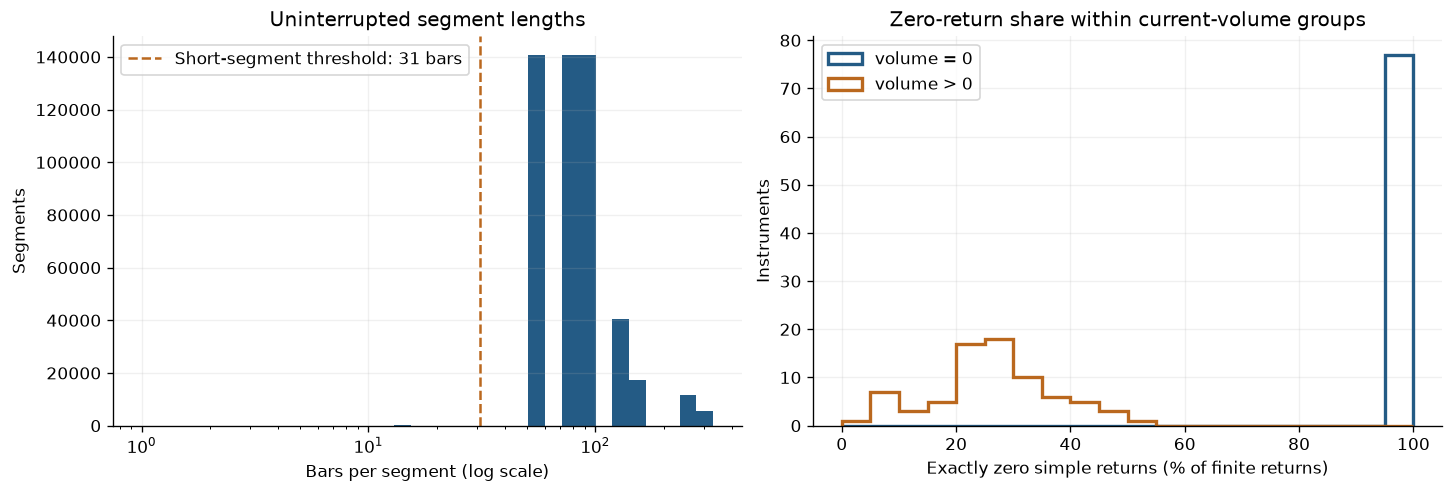

In [10]:
fig, axes = plt.subplots(1,2,figsize=(12,4),layout="constrained")
lengths = segments_all.rows.to_numpy()
axes[0].hist(lengths, bins=np.geomspace(1,max(2,lengths.max()+1),35),color="#245b85")
axes[0].axvline(31,color="#ba681e",linestyle="--",label="Short-segment threshold: 31 bars")
axes[0].set(xscale="log",title="Uninterrupted segment lengths",xlabel="Bars per segment (log scale)",ylabel="Segments")
axes[0].legend()
volume_view = audit_results["zero_volume_comparison"].query("return_type == 'simple_return'")
for group,color in [("volume = 0","#245b85"),("volume > 0","#ba681e")]:
    values=volume_view.loc[volume_view.volume_group.eq(group),"return_zero_pct"].dropna()
    axes[1].hist(values,bins=np.linspace(0,100,21),histtype="step",linewidth=2,label=group,color=color)
axes[1].set(title="Zero-return share within current-volume groups",xlabel="Exactly zero simple returns (% of finite returns)",ylabel="Instruments")
axes[1].legend()
fig.savefig(RESEARCH_DIR/"segment_volume_diagnostics.png",dpi=160)
plt.show()

## Correlation multitool: interface and exact time direction
`corr(x, y, lags, transform, y_transform, ...)` computes `corr(Tx(x[t]), Ty(y[t-lag]))`.
Positive lag means the right feature is in the past; negative lag places it in the future; lag zero is contemporaneous.
An omitted `y` gives autocorrelation; different features give cross-correlation. Correlation is symmetric in values, but exchanging features at a fixed nonzero lag changes the temporal question.

Transforms `identity`, `abs` and `square`, custom summary statistics/quantiles, positive/negative/zero lags, and optional within-segment rolling/nonoverlapping windows remain available.
The exhaustive significance screen below uses **only abs/abs and whole segments**. Window diagnostics have no attached significance claim.

In [11]:
class FeatureArrays(Mapping):
    """Lazy per-instrument arrays from this notebook's single feature artifact."""
    def __init__(self, path, instruments):
        self.path, self.files = Path(path), tuple(instruments)
    def __getitem__(self, filename):
        if filename not in self.files:
            raise KeyError(filename)
        frame = pd.read_parquet(self.path, filters=[("instrument","=",filename)])
        frame = frame.sort_values(["date","ID"],kind="stable").rename(columns=RAW_FIELDS)
        return {column:frame[column].to_numpy() for column in frame.columns if column != "instrument"}
    def __iter__(self): return iter(self.files)
    def __len__(self): return len(self.files)

arrays_by_file = FeatureArrays(FEATURE_PATH, files)

### Configurable summary statistics and quantiles

In [12]:
def _quantile_label(q):
    text = format(Decimal(str(q)) * 100, "f")
    if "." in text:
        text = text.rstrip("0").rstrip(".")
    return text + "%"

In [13]:
def _statistic_options(statistics, quantiles, std_ddof, quantile_method):
    names = [statistics] if isinstance(statistics, str) else list(statistics)
    if any(not isinstance(name, str) or name.strip().lower() not in DEFAULT_STATISTICS for name in names):
        raise ValueError(f"statistics must contain names from {DEFAULT_STATISTICS}")
    names = list(dict.fromkeys(name.strip().lower() for name in names))
    requested = [quantiles] if isinstance(quantiles, Real) else list(quantiles)
    levels = []
    for q in requested:
        if isinstance(q, (bool, np.bool_)) or not isinstance(q, Real) or not np.isfinite(q) or not 0 <= q <= 1:
            raise ValueError("quantiles must contain probabilities between 0 and 1, e.g. [0.1, 0.5, 0.9]")
        value = float(q)
        if value not in levels:
            levels.append(value)
    if isinstance(std_ddof, (bool, np.bool_)) or not isinstance(std_ddof, Integral) or std_ddof < 0:
        raise ValueError("std_ddof must be a nonnegative integer; usually 1 (sample) or 0 (population)")
    if quantile_method not in QUANTILE_METHODS:
        raise ValueError(f"quantile_method must be one of {QUANTILE_METHODS}")
    return names, levels, int(std_ddof)

In [14]:
def _correlation_distribution(values, statistics, quantiles, std_ddof, quantile_method):
    """Equally weighted finite coefficients; NaNs remain counted as undefined units."""
    series = pd.Series(np.asarray(values, dtype=float))
    finite = series.loc[np.isfinite(series)]
    result = {"count": len(finite), "missing_or_nonfinite": len(series)-len(finite)}
    for name in statistics:
        if name == "std":
            value = finite.std(ddof=std_ddof) if len(finite) > std_ddof else np.nan
        elif name == "excess_kurtosis":
            value = finite.kurt()
        else:
            value = getattr(finite, name)()
        if name in {"skew", "excess_kurtosis"} and len(finite) and finite.min() == finite.max():
            value = np.nan
        result[name] = value
    if quantiles:
        result.update(zip((_quantile_label(q) for q in quantiles),
                          finite.quantile(quantiles, interpolation=quantile_method).to_numpy()))
    return result

### Result tables and export

In [15]:
@dataclass
class AutocorrelationResult:
    summary: pd.DataFrame
    details: pd.DataFrame
    parameters: dict

    def table(self, metric="corr_mean", **filters):
        """One row per file. metric accepts 'mean', 'std', '10%' or a list of metrics.

        Existing corr_* names still work. A list creates (setting, metric) columns;
        metric=None selects all statistics/quantiles configured for this result.
        """
        multiple = metric is None or not isinstance(metric, str)
        if metric is None:
            requested = [*self.parameters.get("statistics", DEFAULT_STATISTICS),
                         *(_quantile_label(q) for q in self.parameters.get("quantiles", DEFAULT_QUANTILES))]
            requested = requested or ["count"]
        else:
            requested = [metric] if isinstance(metric, str) else list(metric)
        if not requested:
            raise ValueError("Choose at least one metric")
        metrics = []
        for name in requested:
            if not isinstance(name, str):
                raise ValueError("Use metric names such as 'mean', 'std', '10%' or 'corr_mean'")
            candidate = name if name in self.summary else "corr_" + name.strip().lower()
            if candidate not in self.summary or candidate in {"file", "setting"}:
                raise ValueError(f"Metric {name!r} was not calculated. Configure statistics/quantiles in corr(...).")
            if candidate not in metrics:
                metrics.append(candidate)
        selected = self.summary
        for column, value in filters.items():
            if column not in selected:
                raise ValueError(f"Unknown filter column: {column}")
            items = [value] if isinstance(value, (str, Integral)) or value is None else list(value)
            selected = selected.loc[selected[column].isin(items)]
        settings = selected["setting"].drop_duplicates()
        if not multiple:
            return selected.pivot(index="file", columns="setting", values=metrics[0]).reindex(columns=settings).sort_index()
        result = selected.pivot(index="file", columns="setting", values=metrics).swaplevel(0, 1, axis=1)
        columns = pd.MultiIndex.from_product([settings, metrics], names=["setting", "metric"])
        return result.reindex(columns=columns).sort_index()

    def save(self, directory):
        """Write analysis outputs only; never write back to source files."""
        import json
        directory = Path(directory)
        directory.mkdir(parents=True, exist_ok=True)
        paths = {"summary": directory / "summary.csv", "details": directory / "details.csv",
                 "statistics_by_file": directory / "statistics_by_file.csv"}
        self.summary.to_csv(paths["summary"], index=False)
        self.details.to_csv(paths["details"], index=False)
        wide = self.table(None)
        wide.columns = [f"{setting} :: {metric}" for setting, metric in wide.columns]
        wide.to_csv(paths["statistics_by_file"])
        if "corr_mean" in self.summary:
            paths["mean_by_file"] = directory / "mean_by_file.csv"
            self.table("mean").to_csv(paths["mean_by_file"])
        (directory / "parameters.json").write_text(json.dumps(self.parameters, ensure_ascii=False, indent=2) + "\n")
        return paths

### Input and segment validation

In [16]:
def _integers(value, name, *, allow_none=False, positive=False):
    try:
        items = [value] if value is None or isinstance(value, Integral) else list(value)
    except TypeError as error:
        raise ValueError(f"{name} must contain integers") from error
    if not items:
        raise ValueError(f"{name} must not be empty")
    result = []
    for item in items:
        if item is None and allow_none:
            cleaned = None
        elif isinstance(item, Integral) and not isinstance(item, (bool, np.bool_)):
            cleaned = int(item)
            if positive and cleaned < 1:
                raise ValueError(f"{name} must contain positive integers")
        else:
            raise ValueError(f"{name} must contain integers" + (" or None" if allow_none else ""))
        if cleaned not in result:
            result.append(cleaned)
    return result

In [17]:
def _resolve_feature(name, arrays):
    normalize = lambda text: str(text).strip().lower().replace(" ", "_")
    aliases = {normalize(key): value for key, value in RAW_FIELDS.items()}
    names = {normalize(key): key for key in arrays}
    normalized = normalize(name)
    canonical = aliases.get(normalized, names.get(normalized))
    if canonical not in arrays or canonical in {"ID", "date", "symbol", "segment_id", "segment_start", "delta_minutes"}:
        raise ValueError(f"Unknown feature {name!r}. Available standard features: {AVAILABLE_FEATURES}")
    return canonical

In [18]:
def _segment_layout(arrays, saved):
    ids = np.asarray(arrays["segment_id"])
    if ids.ndim != 1 or not len(ids) or not np.issubdtype(ids.dtype, np.integer):
        raise ValueError("segment_id must be a nonempty integer array")
    starts = np.r_[0, np.flatnonzero(ids[1:] != ids[:-1]) + 1]
    ends = np.r_[starts[1:], len(ids)]  # exclusive
    if len(np.unique(ids[starts])) != len(starts):
        raise ValueError("An existing segment_id recurs in disconnected runs")
    saved = saved.copy().set_index("segment_id")
    if not saved.index.is_unique:
        raise ValueError("segments.csv contains duplicate segment IDs")
    if set(saved.index) != set(ids[starts]):
        raise ValueError("arrays_by_file and segments.csv have different segment IDs")
    saved = saved.loc[ids[starts]].reset_index()
    np.testing.assert_array_equal(saved.rows, ends - starts)
    dates = np.asarray(arrays["date"], dtype="datetime64[ns]")
    symbols = np.asarray(arrays["symbol"])
    source_ids = np.asarray(arrays["ID"])
    if any(len(a) != len(ids) for a in [dates, symbols, source_ids]):
        raise ValueError("Input arrays have different lengths")
    inside = ids[1:] == ids[:-1]
    if np.any(np.isnat(dates)) or np.any(np.diff(dates)[inside] != np.timedelta64(1, "m")):
        raise ValueError("Existing segments are not continuous minute bars; preprocessing was not changed")
    if np.any(symbols[1:][inside] != symbols[:-1][inside]):
        raise ValueError("An existing segment crosses a symbol change")
    np.testing.assert_array_equal(pd.to_datetime(saved.start).to_numpy(), dates[starts])
    np.testing.assert_array_equal(pd.to_datetime(saved.end).to_numpy(), dates[ends - 1])
    np.testing.assert_array_equal(saved.first_ID, source_ids[starts])
    np.testing.assert_array_equal(saved.last_ID, source_ids[ends - 1])
    groups = np.repeat(np.arange(len(starts)), ends - starts)
    return saved, starts, ends, groups, dates, source_ids

### Fixed-position pairs and transforms

In [19]:
def _pair_arrays(values, groups, lag, against=None):
    """Pair x[t] with y[t-lag], stored at the later endpoint for window containment."""
    against = values if against is None else against
    distance = abs(lag)
    x = np.full(len(values), np.nan)
    y = np.full(len(values), np.nan)
    if distance >= len(values):
        return x, y
    later = np.arange(distance, len(values))
    earlier = later - distance
    current, shifted = (later, earlier) if lag >= 0 else (earlier, later)
    valid = (groups[later] == groups[earlier]) & np.isfinite(values[current]) & np.isfinite(against[shifted])
    x[later[valid]], y[later[valid]] = values[current[valid]], against[shifted[valid]]
    return x, y

In [20]:
def _transforms(value, name):
    items = [value] if isinstance(value, str) else list(value)
    if not items or any(item not in TRANSFORMS for item in items):
        raise ValueError(f"{name} must contain {TRANSFORMS}")
    return list(dict.fromkeys(items))

In [21]:
def _values(arrays, field, transform, length):
    try:
        values = np.array(arrays[field], dtype=float, copy=True)
    except (ValueError, TypeError) as error:
        raise ValueError(f"Feature {field} must be numeric") from error
    if values.ndim != 1 or len(values) != length:
        raise ValueError(f"Feature {field} is not aligned with saved segments")
    with np.errstate(over="ignore", invalid="ignore"):
        if transform == "abs": values = np.abs(values)
        elif transform == "square": values = np.square(values)
    values[~np.isfinite(values)] = np.nan
    return values

### Stable within-segment Pearson coefficients

In [22]:
def _group_correlations(x, y, groups, n_groups, min_pairs):
    valid = np.isfinite(x) & np.isfinite(y)
    g, a, b = groups[valid], x[valid], y[valid]
    count = np.bincount(g, minlength=n_groups)
    origin_x, origin_y = np.zeros(n_groups), np.zeros(n_groups)
    present, first = np.unique(g, return_index=True)
    origin_x[present], origin_y[present] = a[first], b[first]
    a, b = a - origin_x[g], b - origin_y[g]
    mean_x = np.divide(np.bincount(g, weights=a, minlength=n_groups), count,
                       out=np.zeros(n_groups), where=count > 0)
    mean_y = np.divide(np.bincount(g, weights=b, minlength=n_groups), count,
                       out=np.zeros(n_groups), where=count > 0)
    a, b = a - mean_x[g], b - mean_y[g]
    xx = np.bincount(g, weights=a*a, minlength=n_groups)
    yy = np.bincount(g, weights=b*b, minlength=n_groups)
    xy = np.bincount(g, weights=a*b, minlength=n_groups)
    norm = np.sqrt(xx*yy)
    corr = np.divide(xy, norm, out=np.full(n_groups, np.nan), where=(count >= min_pairs) & (norm > 0))
    return np.clip(corr, -1, 1), count, (xx == 0) | (yy == 0), origin_x, origin_y

### Optional windows contained within segments

In [23]:
def _units(starts, ends, window, step):
    if window is None:
        return np.arange(len(starts)), starts.copy(), ends - 1, np.ones(len(starts), dtype=bool)
    # One diagnostic row is retained for every segment too short for a complete window.
    sizes = ends - starts
    counts = np.maximum(1, (sizes-window)//step + 1)
    segments = np.repeat(np.arange(len(starts)), counts)
    offsets = np.arange(counts.sum()) - np.repeat(np.r_[0, counts.cumsum()[:-1]], counts)
    complete = sizes[segments] >= window
    left = starts[segments] + offsets*step
    right = np.where(complete, left+window-1, ends[segments]-1)
    return segments, left, right, complete

In [24]:
def _window_correlations(x, y, groups, origins, left, right, complete, window, lag, min_pairs):
    n_units, distance = len(left), abs(lag)
    corr, pairs = np.full(n_units, np.nan), np.zeros(n_units, dtype=np.int64)
    constant = np.zeros(n_units, dtype=bool)
    pair_window = window - distance
    if pair_window <= 0 or not complete.any():
        return corr, pairs, constant
    # Subtract a segment-specific reference before rolling moments (e.g. large price levels).
    a = pd.Series(x - origins[0][groups])
    b = pd.Series(y - origins[1][groups])
    positions = right[complete]
    pairs[complete] = a.rolling(pair_window, min_periods=0).count().to_numpy()[positions].astype(np.int64)
    if pair_window < min_pairs:
        return corr, pairs, constant
    rolling = a.rolling(pair_window, min_periods=min_pairs)
    values = rolling.corr(b).to_numpy()[positions]
    ax = rolling.max().to_numpy()[positions] - rolling.min().to_numpy()[positions]
    by = b.rolling(pair_window, min_periods=min_pairs)
    bx = by.max().to_numpy()[positions] - by.min().to_numpy()[positions]
    constant[complete] = (ax == 0) | (bx == 0)
    corr[complete] = values
    enough = complete & (pairs >= min_pairs) & ~constant
    # Re-evaluate numerical degeneracies directly without filling undefined input values.
    suspect = enough & (~np.isfinite(corr) | (np.abs(corr) > 1 + 1e-10))
    for i in np.flatnonzero(suspect):
        start, end = left[i] + distance, right[i] + 1
        valid = np.isfinite(x[start:end]) & np.isfinite(y[start:end])
        corr[i] = pearson(x[start:end][valid], y[start:end][valid])
    corr[~enough] = np.nan
    return np.clip(corr, -1, 1), pairs, constant

### Reusable correlation API

In [25]:
def autocorrelations(arrays_by_file, feature="log_return", lags=(1,), windows=None,
                     transform="identity", mode="rolling", step=1, min_pairs=2,
                     files=None, details_files=None,
                     segments_by_file=None, progress=False, against=None, against_transform=None,
                     statistics=DEFAULT_STATISTICS, quantiles=DEFAULT_QUANTILES,
                     std_ddof=1, quantile_method="linear"):
    """Pearson corr(x[t], x[t-lag]) with both endpoints inside one saved segment/window.

    feature: numeric feature name or list; transform: identity / abs / square or a list.
    against=None: each feature versus itself with the same transform on both sides.
    against=feature/list: corr(transform(x[t]), against_transform(y[t-lag])).
    An explicit against defaults to an identity right transform. Transform lists
    are compared separately; an explicit right list forms a Cartesian product.
    windows=None: each entire segment. An integer/list: full windows of W minute BARS.
    windows may mix None and integers. Positive/negative/zero lags use fixed bar positions.
    mode='rolling' advances full windows by step; 'nonoverlap' advances by W.
    min_pairs is the minimum finite endpoint pairs required for a coefficient (>=2).
    No dropna before shifting: a lag of k always spans exactly k existing minute bars.
    details_files=None retains summaries only; list filenames or 'all' to retain details.
    statistics selects distribution metrics (mean, std, median, min, max, skew, excess_kurtosis).
    quantiles contains arbitrary probabilities in [0,1]; [] omits quantiles.
    std_ddof=1 is sample std, 0 is population std. quantile_method controls interpolation.
    Distribution metrics describe finite segment/window coefficients, with equal unit weights.

    summary pooled_corr uses each finite pair within the original segments once,
    independently of window length/step. Window summary moments weight each defined
    window equally; overlapping windows are dependent. No significance test is implied.
    """
    lags = _integers(lags, "lags")
    windows = _integers(windows, "windows", allow_none=True, positive=True)
    statistics, quantiles, std_ddof = _statistic_options(statistics, quantiles, std_ddof, quantile_method)
    if not isinstance(step, Integral) or not isinstance(min_pairs, Integral):
        raise ValueError("step and min_pairs must be individual integers")
    step = _integers(step, "step", positive=True)[0]
    min_pairs = _integers(min_pairs, "min_pairs", positive=True)[0]
    if min_pairs < 2:
        raise ValueError("min_pairs must be at least 2")
    transforms = _transforms(transform, "transform")
    right_transforms = None if against_transform is None else _transforms(against_transform, "against_transform")
    if mode not in {"rolling", "nonoverlap"}:
        raise ValueError("mode must be rolling or nonoverlap")
    if mode == "nonoverlap" and step != 1:
        raise ValueError("For nonoverlap windows omit step; the effective step is the window length")
    features = [feature] if isinstance(feature, str) else list(feature)
    right_features = None if against is None else [against] if isinstance(against, str) else list(against)
    if right_features == []:
        raise ValueError("against must not be empty")
    selected = list(arrays_by_file) if files is None else ([files] if isinstance(files, str) else list(files))
    if not selected or not features or len(set(selected)) != len(selected):
        raise ValueError("Choose nonempty features and unique files")
    unknown = set(selected) - set(arrays_by_file)
    if unknown:
        raise ValueError(f"Unknown files: {sorted(unknown)}")
    detail_set = set(selected) if details_files == "all" else set(
        [] if details_files is None else [details_files] if isinstance(details_files, str) else details_files)
    if detail_set - set(selected):
        raise ValueError("details_files must be included in files")
    records, detail_parts = [], []
    for number, filename in enumerate(selected, 1):
        arrays = arrays_by_file[filename]
        if segments_by_file is None:
            raise ValueError("Pass segments_by_file from Notebook 2; no source-directory fallback is allowed")
        saved = segments_by_file[filename]
        saved, starts, ends, groups, dates, source_ids = _segment_layout(arrays, saved)
        resolved = [_resolve_feature(name, arrays) for name in features]
        if len(set(resolved)) != len(resolved):
            raise ValueError("Feature aliases select the same column more than once")
        resolved_right = None if right_features is None else [_resolve_feature(name, arrays) for name in right_features]
        if resolved_right is not None and len(set(resolved_right)) != len(resolved_right):
            raise ValueError("Right feature aliases select the same column more than once")
        jobs = [(field, other, left_transform, right_transform)
                for field in resolved for left_transform in transforms
                for other in ([field] if resolved_right is None else resolved_right)
                for right_transform in (right_transforms if right_transforms is not None else
                                         [left_transform] if resolved_right is None else ["identity"])]
        for field, other, left_transform, right_transform in jobs:
            values = _values(arrays, field, left_transform, len(groups))
            is_auto = field == other and left_transform == right_transform
            right_values = values if is_auto else _values(arrays, other, right_transform, len(groups))
            nonfinite_values = int((~np.isfinite(values)).sum())
            for lag in lags:
                x, y = _pair_arrays(values, groups, lag, right_values)
                whole_corr, whole_pairs, whole_constant, ox, oy = _group_correlations(x, y, groups, len(saved), min_pairs)
                valid = np.isfinite(x) & np.isfinite(y)
                pooled = pearson(x[valid], y[valid]) if valid.sum() >= min_pairs else np.nan
                for window in windows:
                    actual_step = 0 if window is None else window if mode == "nonoverlap" else step
                    unit_group, left, right, complete = _units(starts, ends, window, actual_step)
                    if window is None:
                        corr, pairs, constant = whole_corr.copy(), whole_pairs.copy(), whole_constant.copy()
                    else:
                        corr, pairs, constant = _window_correlations(
                            x, y, groups, (ox, oy), left, right, complete, window, lag, min_pairs)
                    potential = np.where(complete, np.maximum(right-left+1-abs(lag), 0), 0)
                    status = np.full(len(corr), "ok", dtype=object)
                    status[~np.isfinite(corr)] = "numerical_undefined"
                    status[constant] = "constant_pair_series"
                    status[pairs < min_pairs] = "insufficient_finite_pairs"
                    status[potential == 0] = "lag_too_large_for_unit"
                    status[~complete] = "segment_shorter_than_window"
                    size_label = "segment" if window is None else f"{window} bars/{mode}/step={actual_step}"
                    setting = (f"{field} | {left_transform} | lag={lag} | {size_label}" if is_auto else
                               f"{left_transform}({field})[t] vs {right_transform}({other})[t-({lag})] | {size_label}")
                    config = dict(file=filename, feature=field, transform=left_transform, lag=lag,
                                  y_feature=other, y_transform=right_transform, kind="auto" if is_auto else "cross",
                                  window_bars=0 if window is None else window,
                                  mode="segment" if window is None else mode, step=actual_step,
                                  min_pairs=min_pairs, setting=setting)
                    record = {**config, "segments": len(saved), "bars": len(groups),
                              "nonfinite_feature_values": nonfinite_values, "units": len(corr),
                              "nonfinite_y_values": int((~np.isfinite(right_values)).sum()),
                              "full_units": int(complete.sum()), "segments_without_full_window": int((~complete).sum()),
                              "pair_count_all_segments": int(whole_pairs.sum()), "pooled_corr": pooled,
                              **{f"corr_{key}": value for key, value in _correlation_distribution(
                                  corr, statistics, quantiles, std_ddof, quantile_method).items()}}
                    for reason in ["insufficient_finite_pairs", "constant_pair_series", "lag_too_large_for_unit", "numerical_undefined"]:
                        record[reason] = int((status == reason).sum())
                    records.append(record)
                    if filename in detail_set:
                        part = pd.DataFrame({
                            "segment_id": saved.segment_id.to_numpy()[unit_group],
                            "symbol": saved.symbol.to_numpy()[unit_group],
                            "start": dates[left], "end": dates[right], "bars": right-left+1,
                            "first_ID": source_ids[left], "last_ID": source_ids[right],
                            "full_window": complete, "possible_pairs": potential,
                            "pairs": pairs, "corr": corr, "status": status,
                        })
                        for key, value in config.items(): part[key] = value
                        part["unit_in_segment"] = part.groupby("segment_id", sort=False).cumcount() + 1
                        detail_parts.append(part)
        if progress and (number % 10 == 0 or number == len(selected)):
            print(f"Correlations: {number}/{len(selected)} files")
    parameters = dict(features=features, y_features=right_features, lags=lags, windows=windows,
                      transforms=transforms, y_transforms=right_transforms,
                      statistics=statistics, quantiles=quantiles, std_ddof=std_ddof,
                      quantile_method=quantile_method,
                      mode=mode, step=step, min_pairs=min_pairs, files=selected,
                      details_files=sorted(detail_set), preprocessing_changed=False,
                      correlation="corr(transform(x[t]), y_transform(y[t-lag])); finite endpoints at exact bar lag",
                      pooled_scope="all within-segment pairs once, independent of window settings")
    detail_columns = ["segment_id", "symbol", "start", "end", "bars", "first_ID", "last_ID",
                      "full_window", "possible_pairs", "pairs", "corr", "status", "file", "feature",
                      "transform", "y_feature", "y_transform", "kind", "lag", "window_bars", "mode", "step", "min_pairs", "setting", "unit_in_segment"]
    return AutocorrelationResult(pd.DataFrame(records),
                                 pd.concat(detail_parts, ignore_index=True) if detail_parts else pd.DataFrame(columns=detail_columns),
                                 parameters)

In [26]:
def correlations(arrays_by_file, x="log_return", y=None, lags=(1,), transform="identity",
                 y_transform=None, **kwargs):
    """General entry point: corr(Tx(x[t]), Ty(y[t-lag])). y=None selects autocorrelation.

    x/y can be feature names or lists. transform/y_transform can be names or lists.
    When y=None and y_transform=None, each transform is applied to both copies of x.
    With explicit y and omitted y_transform, y keeps its original values.
    Positive lag means y is in the past; negative lag means y is in the future.
    All remaining options (files, details_files, windows, min_pairs, etc.) are shared.
    """
    return autocorrelations(arrays_by_file, feature=x, against=y, lags=lags,
                            transform=transform, against_transform=y_transform, **kwargs)

In [27]:
def corr(x="log_return", y=None, **kwargs):
    return correlations(arrays_by_file, x=x, y=y, segments_by_file=segments_by_file, **kwargs)

return_autocorrelations = corr(x=["simple_return","log_return"], transform=["identity","abs"],
    lags=SCAN_LAGS, progress=True, statistics=["mean","std","median"], quantiles=[.05,.95])
return_autocorrelations.save(RESEARCH_DIR / "return_autocorrelations")
show_table(return_autocorrelations.summary[["file","feature","transform","lag","corr_count","corr_mean","corr_std","pooled_corr"]],
    "Signed and absolute return autocorrelations")

cross_example = corr(x="log_return",y="Volume",transform="abs",y_transform="identity",
    lags=[-1,0,1,5],files=[files[0]],details_files=[files[0]],statistics=["mean","std"],quantiles=[.1,.5,.9])
cross_example.save(RESEARCH_DIR / "cross_correlation_example")
show_table(cross_example.summary[["file","feature","y_feature","lag","corr_count","corr_mean","corr_std","pooled_corr"]],
    "Time direction example: abs(log return)[t] versus Volume[t-lag]")

Correlations: 10/77 files


Correlations: 20/77 files


Correlations: 30/77 files


Correlations: 40/77 files


Correlations: 50/77 files


...

Correlations: 70/77 files


Correlations: 77/77 files


file,feature,transform,lag,corr_count,corr_mean,corr_std,pooled_corr
A9999.XDCE.csv,simple_return,identity,1,13733,-0.131180,0.136163,-0.091596
A9999.XDCE.csv,simple_return,identity,2,13733,-0.026403,0.127819,-0.002078
A9999.XDCE.csv,simple_return,identity,3,13733,-0.013960,0.125392,0.004074
A9999.XDCE.csv,simple_return,identity,5,13733,-0.015975,0.126829,-0.006790
A9999.XDCE.csv,simple_return,identity,10,13730,-0.006875,0.128520,0.001951
A9999.XDCE.csv,simple_return,abs,1,13733,0.113558,0.144153,0.302078
A9999.XDCE.csv,simple_return,abs,2,13733,0.059034,0.139963,0.248668
A9999.XDCE.csv,simple_return,abs,3,13733,0.046918,0.135368,0.234494
A9999.XDCE.csv,simple_return,abs,5,13733,0.034144,0.130118,0.219225
A9999.XDCE.csv,simple_return,abs,10,13730,0.013259,0.129924,0.188020


Showing 15 of 1,540 rows; the complete table is exported.


file,feature,y_feature,lag,corr_count,corr_mean,corr_std,pooled_corr
A9999.XDCE.csv,log_return,Volume,-1,13733,0.279123,0.169489,0.376552
A9999.XDCE.csv,log_return,Volume,0,13736,0.460585,0.164369,0.454450
A9999.XDCE.csv,log_return,Volume,1,13733,0.177826,0.161686,0.299777
A9999.XDCE.csv,log_return,Volume,5,13733,0.082528,0.149196,0.237209


## Exhaustive absolute-value screen and significance
For each file, estimate every ordered pair of 13 features at lags 1/2/3/5/10: 845 configurations per instrument.
Each finite segment coefficient receives equal weight; this is not correlation after concatenating disconnected segments.

Test **H0: the mean estimated segment Pearson coefficient equals zero**. Sum centered segment coefficients by their start calendar date, then apply Bartlett HAC at 20 and 60 neighboring observed dates.
Require at least 90 dates with defined coefficients. Retain the common observed-date clock even when a configuration has no defined coefficient on a date.
Use two-sided asymptotic normal p-values and `p_screen = max(p_hac20, p_hac60)`.
Apply **global Benjamini-Yekutieli** correction to every requested instrument/configuration row; undefined p-values count as 1 only for multiplicity accounting and remain missing in the report.
`q_by < 0.05` defines significance. The pointwise 95% interval uses the larger HAC standard error and is not simultaneous.

Short-segment correlation bias, nonstationary price levels and mechanically overlapping volatility windows remain limitations.
All history is used for exploration. A small q-value does not establish causality, effect-size importance or directional profitability.
Method references: [date-group HAC](https://www.statsmodels.org/stable/generated/statsmodels.stats.sandwich_covariance.cov_nw_groupsum.html) and [BY correction](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.false_discovery_control.html).

### Reuse identical transformed values

In [28]:
def _transformed_matrix(arrays, features, transforms):
    """Reuse exactly equal transformed arrays, retaining every requested label."""
    columns, mapping, labels, hashes = [], [], [], {}
    for field in features:
        for transform in transforms:
            value = _values(arrays, field, transform, len(arrays['segment_id']))
            digest = hashlib.sha256(value.tobytes()).hexdigest()
            candidates = hashes.get(digest, [])
            index = next((i for i in candidates
                          if np.array_equal(value, columns[i], equal_nan=True)), None)
            if index is None:
                index = len(columns)
                columns.append(value)
                hashes.setdefault(digest, []).append(index)
            mapping.append(index)
            labels.append((field, transform))
    return np.column_stack(columns), np.array(mapping), labels

### Batched stable Pearson calculation

In [29]:
def _matrix_pearson(x, y, min_pairs):
    """Batch x/y shapes (segments, bars, features), pairwise finite endpoints.

    Subtract a feature origin before computing pairwise centered sums to avoid
    subtracting squared price levels. Near cancellation uses direct two-pass
    Pearson on the original finite pairs. NaNs keep their original positions.
    """
    mx, my = np.isfinite(x), np.isfinite(y)
    ix, iy = mx.argmax(axis=1), my.argmax(axis=1)
    ox = np.take_along_axis(x, ix[:, None, :], axis=1)
    oy = np.take_along_axis(y, iy[:, None, :], axis=1)
    a = np.where(mx, x - np.nan_to_num(ox), 0)
    b = np.where(my, y - np.nan_to_num(oy), 0)
    # Column scaling prevents overflow without altering Pearson correlations.
    ax = np.max(np.abs(a), axis=1, keepdims=True)
    by = np.max(np.abs(b), axis=1, keepdims=True)
    a /= np.where(ax > 0, ax, 1)
    b /= np.where(by > 0, by, 1)
    u, v = mx.astype(float), my.astype(float)
    at, ut = a.swapaxes(1, 2), u.swapaxes(1, 2)
    count = ut @ v
    sx, sy = at @ v, ut @ b
    xx0, yy0, xy0 = (a*a).swapaxes(1, 2) @ v, ut @ (b*b), at @ b
    n = np.maximum(count, 1)
    xx, yy = xx0-sx*sx/n, yy0-sy*sy/n
    xy = xy0-sx*sy/n
    denominator = np.sqrt(np.maximum(xx, 0)*np.maximum(yy, 0))
    result = np.divide(xy, denominator, out=np.full_like(xy, np.nan),
                       where=(count >= min_pairs) & (denominator > 0))
    unstable = (count >= min_pairs) & (
        ((xx0 > 0) & (xx <= 1e-10*xx0)) |
        ((yy0 > 0) & (yy <= 1e-10*yy0)) |
        (np.abs(result) > 1+1e-10))
    for row, i, j in np.argwhere(unstable):
        valid = mx[row, :, i] & my[row, :, j]
        result[row, i, j] = pearson(x[row, valid, i], y[row, valid, j])
    return np.clip(result, -1, 1), count.astype(np.int32)

### Segment-contained lag matrices

In [30]:
def segment_matrix(values, starts, ends, lag, min_pairs=2, batch_size=128):
    """All ordered feature pairs for one lag; both endpoints in saved segment."""
    p = values.shape[1]
    result = np.full((len(starts), p, p), np.nan)
    counts = np.zeros((len(starts), p, p), dtype=np.int32)
    distance = abs(lag)
    for begin in range(0, len(starts), batch_size):
        stop = min(begin+batch_size, len(starts))
        lengths = np.maximum(ends[begin:stop]-starts[begin:stop]-distance, 0)
        if not lengths.max():
            continue
        offsets = np.arange(lengths.max())[None, :]
        idx = starts[begin:stop, None] + offsets
        idx = np.minimum(idx, len(values)-1)
        later = np.minimum(idx+distance, len(values)-1)
        x = values[later if lag >= 0 else idx].copy()
        y = values[idx if lag >= 0 else later].copy()
        x[offsets >= lengths[:, None]] = np.nan
        y[offsets >= lengths[:, None]] = np.nan
        result[begin:stop], counts[begin:stop] = _matrix_pearson(x, y, min_pairs)
    return result, counts

### Date-HAC inference for the mean segment coefficient

In [31]:
def mean_inference(coefficients, segment_dates, bandwidths=(20, 60), min_dates=90):
    """Equal-segment mean; HAC on sums of centered coefficients by start date.

    Calendar dates with any saved segment define the observed-date clock. The
    entire segment belongs to its start date, including overnight segments.
    Every configuration keeps the same date clock, including dates on which its
    coefficients are all undefined (zero score, not an imputed coefficient).
    H0 is the mean of *estimated segment coefficients* being zero, not an
    unbiased population ACF. Two-sided normal p-values are asymptotic.
    """
    r = coefficients.reshape(len(coefficients), -1)
    valid = np.isfinite(r)
    count = valid.sum(axis=0)
    total = np.where(valid, r, 0).sum(axis=0)
    mean = np.divide(total, count, out=np.full(r.shape[1], np.nan), where=count > 0)
    centered = np.where(valid, r-mean, 0)
    std = np.sqrt(np.divide((centered*centered).sum(axis=0), count-1,
                           out=np.full_like(mean, np.nan), where=count > 1))
    date_values = np.asarray(segment_dates, dtype='datetime64[D]')
    dates, date_group = np.unique(date_values, return_inverse=True)
    scores = np.zeros((len(dates), r.shape[1]))
    daily_counts = np.zeros(scores.shape, dtype=np.int32)
    np.add.at(scores, date_group, centered)
    np.add.at(daily_counts, date_group, valid.astype(np.int32))
    active_dates = (daily_counts > 0).sum(axis=0)
    result = dict(corr_count=count, corr_missing_or_nonfinite=len(r)-count,
                  corr_mean=mean, corr_std=std, dates_with_corr=active_dates,
                  observed_dates=np.repeat(len(dates), r.shape[1]))
    base = (scores*scores).sum(axis=0)
    products = {h: (scores[h:]*scores[:-h]).sum(axis=0)
                for h in range(1, min(max(bandwidths), len(dates)-1)+1)}
    for bandwidth in bandwidths:
        effective = min(bandwidth, len(dates)-1)
        meat = base.copy()
        for h in range(1, effective+1):
            meat += 2*(1-h/(effective+1))*products[h]
        # Date-cluster finite-sample factor (one fitted intercept).
        correction = np.divide(active_dates, active_dates-1,
                               out=np.ones_like(mean), where=active_dates > 1)
        se = np.sqrt(np.maximum(meat, 0)*correction) / np.maximum(count, 1)
        eligible = (active_dates >= min_dates) & (count >= 2) & (se > 0) & np.isfinite(se)
        se[~eligible] = np.nan
        z = np.divide(mean, se, out=np.full_like(mean, np.nan), where=eligible)
        result[f'se_hac{bandwidth}'] = se
        result[f'p_hac{bandwidth}'] = 2*norm.sf(np.abs(z))
    return result

### Run all instruments and configurations
This cell recomputes the screen from the feature artifact. There is no dependency on old cached outputs or external scripts.

In [32]:
features, transforms, lags = AVAILABLE_FEATURES, SCAN_TRANSFORMS, SCAN_LAGS
bandwidths, min_pairs, min_dates, alpha = SCAN_BANDWIDTHS, SCAN_MIN_PAIRS, SCAN_MIN_DATES, SCAN_ALPHA
out, progress = SCAN_DIR, True
feature_input_hash = file_hash(FEATURE_PATH)
records, aliases = [], []
started = time.monotonic()
for file_number, filename in enumerate(files, 1):
    arrays = arrays_by_file[filename]
    saved = segments_by_file[filename]
    saved, starts, ends, _, _, _ = _segment_layout(arrays, saved)
    fields = [_resolve_feature(f, arrays) for f in features]
    if len(set(fields)) != len(fields):
        raise ValueError('Aliases select the same feature more than once')
    values, mapping, labels = _transformed_matrix(arrays, fields, transforms)
    canonical_labels = [labels[mapping.tolist().index(i)] for i in range(values.shape[1])]
    for (field, transform), canonical in zip(labels, mapping):
        aliases.append(dict(file=filename, feature=field, transform=transform,
                            canonical_feature=canonical_labels[canonical][0],
                            canonical_transform=canonical_labels[canonical][1]))
    file_parts = []
    with threadpool_limits(limits=1):
        for lag in lags:
            coefficients, pairs = segment_matrix(values, starts, ends, lag, min_pairs)
            stats = mean_inference(coefficients, saved.start, bandwidths, min_dates)
            p = values.shape[1]
            finite = np.isfinite(coefficients)
            stats['pair_count_all_segments'] = pairs.sum(axis=0).ravel()
            stats['segments_with_2_or_3_pairs'] = ((pairs <= 3) & finite).sum(axis=0).ravel()
            stats['segments_shorter_than_31'] = (finite & ((ends-starts) < 31)[:, None, None]).sum(axis=0).ravel()
            stats['positive_corr_fraction'] = np.divide(
                (coefficients > 0).sum(axis=0).ravel(), stats['corr_count'],
                out=np.full(p*p, np.nan), where=stats['corr_count'] > 0)
            flat = coefficients.reshape(len(saved), -1)
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', RuntimeWarning)
                qs = np.nanquantile(flat, [.05, .5, .95], axis=0)
            for name, q in zip(('corr_5%', 'corr_50%', 'corr_95%'), qs):
                stats[name] = q
            # Expand aliases back to every requested label on both sides.
            positions = (mapping[:, None]*p + mapping[None, :]).ravel()
            part = pd.DataFrame({name: data[positions] for name, data in stats.items()})
            left = [a for a in labels for _ in labels]
            right = labels*len(labels)
            part['file'] = filename
            part['feature'] = [a[0] for a in left]
            part['transform'] = [a[1] for a in left]
            part['y_feature'] = [a[0] for a in right]
            part['y_transform'] = [a[1] for a in right]
            part['kind'] = ['auto' if a == b else 'cross' for a, b in zip(left, right)]
            part['lag'] = lag
            part['segments'] = len(saved)
            part['bars'] = len(arrays['segment_id'])
            part['period_start'], part['period_end'] = saved.start.iloc[0], saved.end.iloc[-1]
            part['setting'] = [f'{a[1]}({a[0]})[t] vs {b[1]}({b[0]})[t-{lag}]'
                               for a, b in zip(left, right)]
            part['p_screen'] = part[[f'p_hac{b}' for b in bandwidths]].max(axis=1, skipna=False)
            part['inference_status'] = np.select(
                [part.corr_count.eq(0), part.dates_with_corr.lt(min_dates), part.p_screen.isna()],
                ['no_defined_coefficients', 'too_few_dates', 'zero_or_undefined_standard_error'],
                default='ok')
            # Pointwise interval using the largest sensitivity SE; not simultaneous.
            se_max = part[[f'se_hac{b}' for b in bandwidths]].max(axis=1, skipna=False)
            part['ci95_low'] = part.corr_mean - norm.ppf(.975)*se_max
            part['ci95_high'] = part.corr_mean + norm.ppf(.975)*se_max
            file_parts.append(part)
            del coefficients, pairs, flat, finite
    file_result = pd.concat(file_parts, ignore_index=True)
    file_result.to_parquet(out/'by_file'/f'{Path(filename).stem}.parquet', index=False)
    records.append(file_result)
    del values, arrays
    if progress:
        print(f'{file_number:2d}/{len(files)}: {filename}; {len(file_result):,} configurations; '
              f'{time.monotonic()-started:.0f} seconds', flush=True)

 1/77: A9999.XDCE.csv; 845 configurations; 2 seconds


 2/77: AG9999.XSGE.csv; 845 configurations; 6 seconds


 3/77: AL9999.XSGE.csv; 845 configurations; 9 seconds


 4/77: AP9999.XZCE.csv; 845 configurations; 9 seconds


 5/77: AU9999.XSGE.csv; 845 configurations; 13 seconds


...

73/77: WS9999.XZCE.csv; 845 configurations; 80 seconds


74/77: WT9999.XZCE.csv; 845 configurations; 81 seconds


75/77: Y9999.XDCE.csv; 845 configurations; 83 seconds


76/77: ZC9999.XZCE.csv; 845 configurations; 84 seconds


77/77: ZN9999.XSGE.csv; 845 configurations; 87 seconds


### Global multiplicity correction and complete exports
The additional view excluding `Open[t]` versus `Close[t-1]` is a reporting filter only. Its p/q-values retain the correction over the complete original screen.

In [33]:
scan_results = pd.concat(records, ignore_index=True)
defined = scan_results.p_screen.notna()
adjusted = false_discovery_control(scan_results.p_screen.fillna(1).to_numpy(), method="by")
scan_results["q_by"] = np.where(defined,adjusted,np.nan)
scan_results["significant"] = scan_results.q_by.lt(SCAN_ALPHA)
scan_results["abs_corr_mean"] = scan_results.corr_mean.abs()
config = ["feature","transform","y_feature","y_transform","kind","lag","setting"]
scan_results = scan_results[["file",*config,*[c for c in scan_results if c not in ["file",*config]]]]
scan_results.to_parquet(SCAN_DIR/"all_results.parquet",index=False)
scan_results.to_csv(SCAN_DIR/"all_results.csv",index=False)
significant = scan_results.loc[scan_results.significant].sort_values(["abs_corr_mean","q_by"],ascending=[False,True])
significant.to_csv(SIGNIFICANT_PATH,index=False)
exclude = significant.feature.eq("Open") & significant.y_feature.eq("Close") & significant.lag.eq(1)
significant.loc[~exclude].to_csv(SCAN_DIR/"significant_without_open_close_lag1.csv",index=False)
scan_overview = scan_results.groupby(config,sort=False,dropna=False).agg(files=("file","size"),
    files_with_mean=("corr_mean","count"),mean_of_file_means=("corr_mean","mean"),std_of_file_means=("corr_mean","std"),
    min_file_mean=("corr_mean","min"),max_file_mean=("corr_mean","max"),files_tested=("p_screen","count"),
    significant_files=("significant","sum"),defined_segments=("corr_count","sum")).reset_index()
scan_overview.to_csv(SCAN_DIR/"configuration_summary.csv",index=False)
scan_results.pivot(index="file",columns="setting",values="corr_mean").to_csv(SCAN_DIR/"mean_by_file.csv")
for filename, part in scan_results.groupby("file",sort=True):
    part.to_parquet(SCAN_DIR/"by_file"/(Path(filename).stem+".parquet"),index=False)
    part.to_csv(SCAN_DIR/"by_file"/(Path(filename).stem+".csv"),index=False)
    part.loc[part.significant].to_csv(SCAN_DIR/"by_file"/(Path(filename).stem+"_significant.csv"),index=False)
pd.DataFrame(aliases).to_csv(SCAN_DIR/"equivalent_transforms.csv",index=False)
assert len(scan_results) == len(files)*len(AVAILABLE_FEATURES)**2*len(SCAN_LAGS)
assert file_hash(FEATURE_PATH) == feature_input_hash
print(f"Configurations: {len(scan_results):,}; significant: {len(significant):,}; undefined tests: {scan_results.p_screen.isna().sum():,}")
print(f"Reporting-only Open[t]/Close[t-1] exclusions: {int(exclude.sum())}")

Configurations: 65,065; significant: 42,458; undefined tests: 845
Reporting-only Open[t]/Close[t-1] exclusions: 76


## Results: persistence, cross-feature relationships and significant combinations
The tables distinguish coefficient means, coefficient dispersion, finite segment counts, finite pair counts and adjusted significance.
The heatmap averages instrument-level segment means equally; it does not pool all bars.

lag,1,2,3,5,10
feature,,,,,
Open,0.87713,0.80085,0.73365,0.61498,0.39404
High,0.90366,0.82108,0.75099,0.62906,0.40200
Low,0.90195,0.81801,0.74722,0.62464,0.39757
Close,0.87926,0.80214,0.73443,0.61571,0.39531
Volume,0.39047,0.25589,0.19770,0.14189,0.06988
Turnover,0.39047,0.25590,0.19772,0.14190,0.06990
Open interest,0.96161,0.92437,0.88630,0.81047,0.63649
log_return,0.09419,0.04931,0.03908,0.02795,0.00987
simple_return,0.09419,0.04931,0.03908,0.02795,0.00987


file,feature,y_feature,lag,corr_mean,abs_corr_mean,corr_count,pair_count_all_segments,p_screen,q_by,significant
IC9999.CCFX.csv,Open interest,Open interest,1,0.998253,0.998253,3175,382294,<1e-300,<1e-300,True
IH9999.CCFX.csv,Open interest,Open interest,1,0.998077,0.998077,3175,382294,<1e-300,<1e-300,True
IF9999.CCFX.csv,Open,Close,1,0.997788,0.997788,5657,706782,<1e-300,<1e-300,True
IC9999.CCFX.csv,Open,Close,1,0.996979,0.996979,3173,382294,<1e-300,<1e-300,True
NI9999.XSGE.csv,Open,Close,1,0.996968,0.996968,6254,710405,<1e-300,<1e-300,True
IF9999.CCFX.csv,Open interest,Open interest,1,0.996570,0.996570,5657,706782,<1e-300,<1e-300,True
PP9999.XDCE.csv,Open,Close,1,0.996143,0.996143,6111,476942,<1e-300,<1e-300,True
IC9999.CCFX.csv,Open interest,Open interest,2,0.995600,0.995600,3175,379118,<1e-300,<1e-300,True
AP9999.XZCE.csv,Open,Close,1,0.994898,0.994898,2769,205350,<1e-300,<1e-300,True
IH9999.CCFX.csv,Open interest,Open interest,2,0.994675,0.994675,3175,379118,<1e-300,<1e-300,True


Showing 15 of 42,458 rows; the complete table is exported.


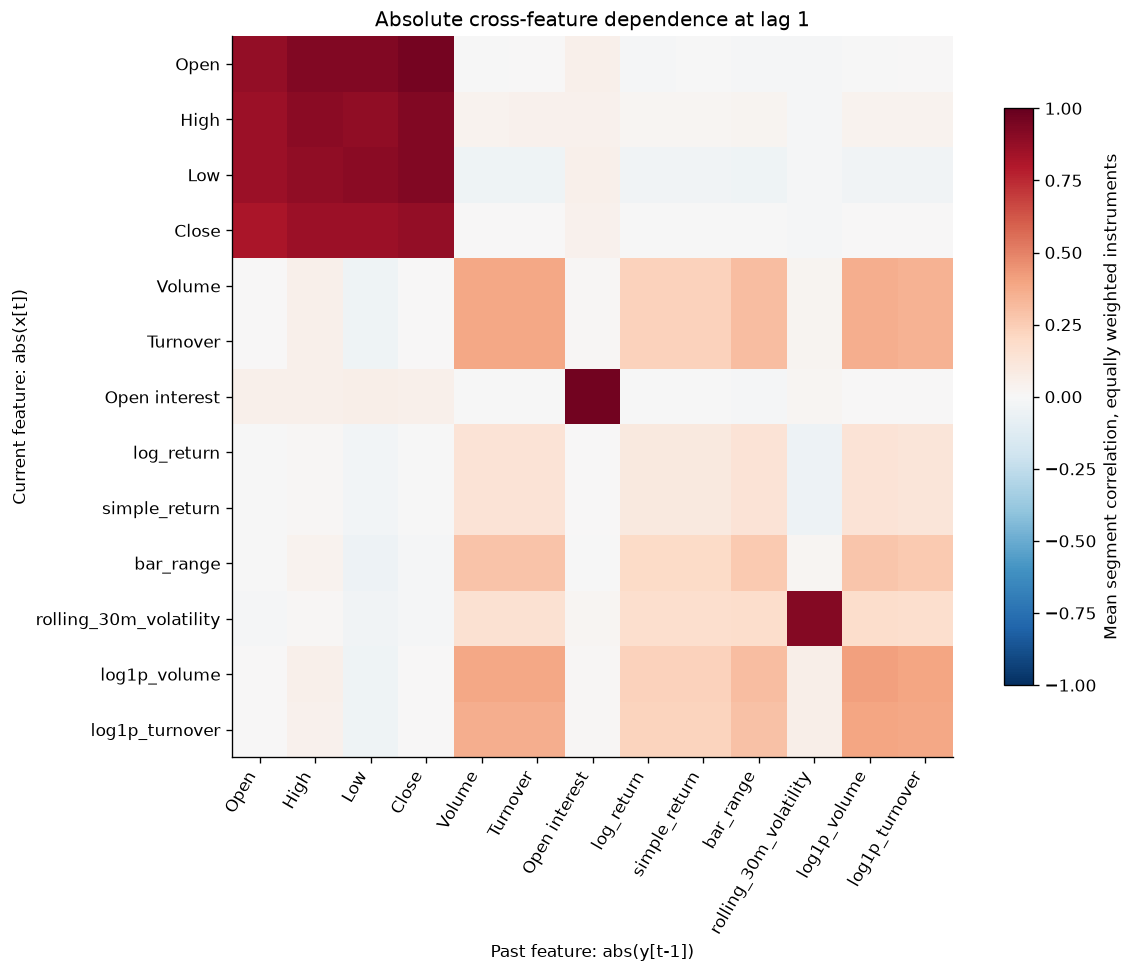

In [34]:
auto_overview = scan_overview.loc[scan_overview.kind.eq("auto")]
auto_means = auto_overview.pivot(index="feature",columns="lag",values="mean_of_file_means").reindex(index=AVAILABLE_FEATURES,columns=SCAN_LAGS)
display(auto_means.style.format("{:.5f}",na_rep="NA").set_caption("Absolute-feature persistence: mean across instruments"))
show_table(significant[["file","feature","y_feature","lag","corr_mean","abs_corr_mean","corr_count",
    "pair_count_all_segments","p_screen","q_by","significant"]],"Significant instrument/configuration combinations")
lag_one = scan_overview.loc[scan_overview.lag.eq(1)].pivot(index="feature",columns="y_feature",values="mean_of_file_means").reindex(index=AVAILABLE_FEATURES,columns=AVAILABLE_FEATURES)
fig, ax = plt.subplots(figsize=(10,8),layout="constrained")
image = ax.imshow(lag_one,vmin=-1,vmax=1,cmap="RdBu_r")
ax.set_xticks(range(len(AVAILABLE_FEATURES)),AVAILABLE_FEATURES,rotation=60,ha="right")
ax.set_yticks(range(len(AVAILABLE_FEATURES)),AVAILABLE_FEATURES)
ax.set(title="Absolute cross-feature dependence at lag 1",xlabel="Past feature: abs(y[t-1])",ylabel="Current feature: abs(x[t])")
ax.grid(False)
fig.colorbar(image,ax=ax,label="Mean segment correlation, equally weighted instruments",shrink=.8)
fig.savefig(RESEARCH_DIR/"absolute_lag1_heatmap.png",dpi=160)
plt.show()

## Research interpretation
Price-level and Open Interest persistence may reflect inertia and trends, not predictive returns. Persistence of rolling volatility also includes mechanical window overlap.
Volume/turnover persistence and range/volume links describe activity and magnitude. In `Volume[t]` versus `abs(return[t-1])`, volume follows the price movement; the reverse ordering asks a different question.
The following table quantifies these patterns from the recomputed screen across all files with a defined mean, not only selected significant files.

In [35]:
relationships = [("Price-level persistence","Close","Close"),
    ("Open Interest persistence","Open interest","Open interest"),
    ("Volatility persistence","rolling_30m_volatility","rolling_30m_volatility"),
    ("Volume persistence","Volume","Volume"),("Turnover persistence","Turnover","Turnover"),
    ("Range following Volume","bar_range","Volume"),("Volume following range","Volume","bar_range"),
    ("Volume following absolute return","Volume","log_return"),
    ("Absolute return following Volume","log_return","Volume")]
interpretation=[]
for label,x,y in relationships:
    row=scan_overview.loc[scan_overview.feature.eq(x)&scan_overview.y_feature.eq(y)&scan_overview.lag.eq(1)].iloc[0]
    interpretation.append({"relationship":label,"current_feature":x,"past_feature":y,"lag":1,
        "mean_of_file_means":row.mean_of_file_means,"defined_files":row.files_with_mean,"significant_files":row.significant_files})
interpretation=pd.DataFrame(interpretation)
interpretation.to_csv(RESEARCH_DIR/"research_findings.csv",index=False)
show_table(interpretation,"Observed dependence patterns",rows=12)
display(Markdown(f"The full screen contains **{len(scan_results):,} configurations**, of which **{len(significant):,}** "
    f"meet the original global BY threshold. **{scan_results.loc[scan_results.corr_count.eq(0),'file'].nunique()} instrument(s)** "
    "have configurations with no defined segment coefficients; these remain missing rather than zero. "
    "Statistical dependence of absolute values does not establish a tradable directional signal. Notebook 3 tests signed future returns."))

relationship,current_feature,past_feature,lag,mean_of_file_means,defined_files,significant_files
Price-level persistence,Close,Close,1,0.879264,76,76
Open Interest persistence,Open interest,Open interest,1,0.961607,76,76
Volatility persistence,rolling_30m_volatility,rolling_30m_volatility,1,0.920733,76,76
Volume persistence,Volume,Volume,1,0.390470,76,76
Turnover persistence,Turnover,Turnover,1,0.390466,76,76
Range following Volume,bar_range,Volume,1,0.286327,76,76
Volume following range,Volume,bar_range,1,0.305156,76,76
Volume following absolute return,Volume,log_return,1,0.229261,76,76
Absolute return following Volume,log_return,Volume,1,0.139449,76,76


The full screen contains **65,065 configurations**, of which **42,458** meet the original global BY threshold. **1 instrument(s)** have configurations with no defined segment coefficients; these remain missing rather than zero. Statistical dependence of absolute values does not establish a tradable directional signal. Notebook 3 tests signed future returns.

## Validation, conclusions and outputs
The matrix screen and the reusable pairwise API must agree for signed lag direction, NaN positions and segment boundaries.
Saved arrays are aligned; no lag or rolling window bridges a symbol change or minute gap. Unknown/constant coefficients remain unknown.

In [36]:
reference_file=files[0]
reference_arrays=arrays_by_file[reference_file]
saved,starts,ends,_,_,_=_segment_layout(reference_arrays,segments_by_file[reference_file])
reference_values,_,_=_transformed_matrix(reference_arrays,["log_return","Volume"],["abs"])
for lag in [0,1,5,-1]:
    matrix,pairs=segment_matrix(reference_values,starts,ends,lag)
    reference=corr(x="log_return",y="Volume",transform="abs",y_transform="abs",lags=[lag],
        files=[reference_file],details_files=[reference_file])
    np.testing.assert_allclose(matrix[:,0,1],reference.details["corr"],rtol=1e-8,atol=1e-10,equal_nan=True)
    np.testing.assert_array_equal(pairs[:,0,1],reference.details.pairs)
assert file_hash(CLEAN_PATH)==clean_input_hash
parameters={"pipeline_stage":2,"input":str(CLEAN_PATH),"input_sha256":clean_input_hash,
    "feature_output":str(FEATURE_PATH),"feature_sha256":file_hash(FEATURE_PATH),
    "segments_output":str(SEGMENTS_PATH),"significant_output":str(SIGNIFICANT_PATH),
    "instruments":files,"rows":int(feature_summary.rows.sum()),"segments":int(feature_summary.segments.sum()),
    "bar_range":"high - low","rolling_returns":30,"rolling_min_periods":30,"std_ddof":1,
    "return_domain":"both closes finite and strictly positive",
    "normalized_return":"simple_return / positive rolling_30m_volatility; otherwise NaN",
    "correlation":"corr(abs(x[t]),abs(y[t-lag]))","features":AVAILABLE_FEATURES,"transforms":SCAN_TRANSFORMS,
    "lags":SCAN_LAGS,"min_pairs":SCAN_MIN_PAIRS,"bandwidths":SCAN_BANDWIDTHS,"min_dates":SCAN_MIN_DATES,
    "p_method":"maximum two-sided date-HAC normal p over bandwidths",
    "multiplicity":"global Benjamini-Yekutieli; undefined p=1 only during adjustment",
    "alpha":SCAN_ALPHA,"family_size":len(scan_results),"significant":len(significant),
    "constant_standardized_moments":"NaN consistently for every feature",
    "raw_rows_deleted":0,"winsorization":False}
(ARTIFACT_DIR/"research_manifest.json").write_text(json.dumps(parameters,indent=2)+"\n")
display(Markdown("**Next:** run `03_strategies_hypotheses.ipynb`.\n\n"
    "Outputs: `artifacts/research_features.parquet`, `artifacts/significant_combinations.csv`, "
    "`artifacts/segments.parquet`, `artifacts/research_manifest.json`, and detailed tables/figures in `artifacts/research/`."))

**Next:** run `03_strategies_hypotheses.ipynb`.

Outputs: `artifacts/research_features.parquet`, `artifacts/significant_combinations.csv`, `artifacts/segments.parquet`, `artifacts/research_manifest.json`, and detailed tables/figures in `artifacts/research/`.